<a href="https://colab.research.google.com/github/AnanyaSKengasur/AI--Pneumonia-Detection/blob/main/pneumonia_hackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle

KGAT_2ddcee142de5707b4372876993ef7ed8


In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your kaggle API token: ")

Enter your kaggle API token: ··········


In [ ]:
!kaggle competitions list

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

In [ ]:
!kaggle competitions download -c rsna-pneumonia-detection-challenge


rsna-pneumonia-detection-challenge.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
import os

print(os.listdir("/content"))


['.config', 'rsna-pneumonia-detection-challenge.zip', 'sample_data']


In [ ]:
!unzip -q /content/rsna-pneumonia-detection-challenge.zip -d /content/rsna_data

replace /content/rsna_data/GCP Credits Request Link - RSNA.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

replace /content/rsna_data/GCP Credits Request Link - RSNA.txt [y]es, [n]o, [A]ll, [N]one, [r]ename:

A


In [ ]:
import os

print(os.listdir("/content/rsna_data"))

['GCP Credits Request Link - RSNA.txt', 'stage_2_sample_submission.csv', 'stage_2_detailed_class_info.csv', 'stage_2_train_images', 'stage_2_test_images', 'stage_2_train_labels.csv']


In [ ]:
import pandas as pd

labels = pd.read_csv(
    "/content/rsna_data/stage_2_train_labels.csv"
)

print(labels.head())
print("\nShape:", labels.shape)

                              patientId      x      y  width  height  Target
0  0004cfab-14fd-4e49-80ba-63a80b6bddd6    NaN    NaN    NaN     NaN       0
1  00313ee0-9eaa-42f4-b0ab-c148ed3241cd    NaN    NaN    NaN     NaN       0
2  00322d4d-1c29-4943-afc9-b6754be640eb    NaN    NaN    NaN     NaN       0
3  003d8fa0-6bf1-40ed-b54c-ac657f8495c5    NaN    NaN    NaN     NaN       0
4  00436515-870c-4b36-a041-de91049b9ab4  264.0  152.0  213.0   379.0       1

Shape: (30227, 6)


In [ ]:
image_labels = labels.groupby("patientId")["Target"].max().reset_index()

print(image_labels.head())
print("\nNumber of X-rays:", len(image_labels))
print("\nClass distribution:")
print(image_labels["Target"].value_counts())

                              patientId  Target
0  0004cfab-14fd-4e49-80ba-63a80b6bddd6       0
1  000924cf-0f8d-42bd-9158-1af53881a557       0
2  000db696-cf54-4385-b10b-6b16fbb3f985       1
3  000fe35a-2649-43d4-b027-e67796d412e0       1
4  001031d9-f904-4a23-b3e5-2c088acd19c6       1

Number of X-rays: 26684

Class distribution:
Target
0    20672
1     6012
Name: count, dtype: int64


In [ ]:
normal = image_labels[image_labels["Target"] == 0]
pneumonia = image_labels[image_labels["Target"] == 1]

# Use all available pneumonia images
# and the same number of normal images
normal_sample = normal.sample(
    n=len(pneumonia),
    random_state=42
)

balanced_data = pd.concat([
    normal_sample,
    pneumonia
])

# Shuffle the dataset
balanced_data = balanced_data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Total images:", len(balanced_data))
print("\nClass distribution:")
print(balanced_data["Target"].value_counts())

Total images: 12024

Class distribution:
Target
0    6012
1    6012
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    balanced_data,
    test_size=0.2,
    random_state=42,
    stratify=balanced_data["Target"]
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))

print("\nTraining distribution:")
print(train_data["Target"].value_counts())

print("\nValidation distribution:")
print(val_data["Target"].value_counts())

Training images: 9619
Validation images: 2405

Training distribution:
Target
1    4810
0    4809
Name: count, dtype: int64

Validation distribution:
Target
0    1203
1    1202
Name: count, dtype: int64


In [ ]:
!pip install -q pydicom

In [ ]:
import pydicom
import matplotlib.pyplot as plt
import os

image_folder = "/content/rsna_data/stage_2_train_images"

patient_id = train_data.iloc[0]["patientId"]

image_path = os.path.join(
    image_folder,
    patient_id + ".dcm"
)

print("Patient ID:", patient_id)
print("Image path:", image_path)
print("File exists:", os.path.exists(image_path))

Patient ID: b3e8a708-d8e1-434e-92ca-5d5e79aca86e
Image path: /content/rsna_data/stage_2_train_images/b3e8a708-d8e1-434e-92ca-5d5e79aca86e.dcm
File exists: True


Image shape: (1024, 1024)


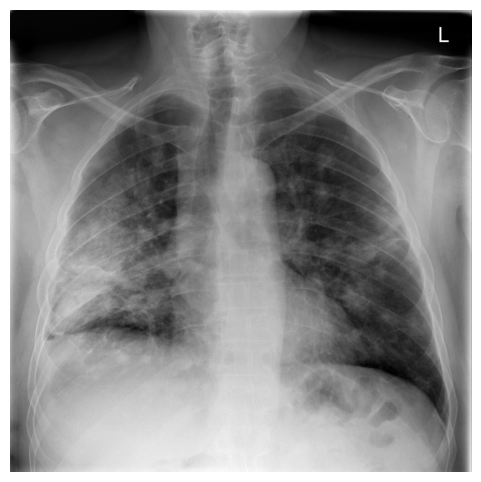

In [ ]:
dicom_image = pydicom.dcmread(image_path)

image = dicom_image.pixel_array

print("Image shape:", image.shape)

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
from PIL import Image

def load_xray(patient_id, image_size=(224, 224)):

    # Path to DICOM file
    path = os.path.join(
        image_folder,
        patient_id + ".dcm"
    )

    # Read DICOM
    dicom = pydicom.dcmread(path)

    # Get pixel data
    image = dicom.pixel_array.astype(np.float32)

    # Normalize to 0–1
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    # Convert to 0–255
    image = (image * 255).astype(np.uint8)

    # Convert to PIL
    image = Image.fromarray(image)

    # Resize
    image = image.resize(image_size)

    # Convert grayscale → RGB
    image = image.convert("RGB")

    # Convert back to NumPy
    return np.array(image)

Processed image shape: (224, 224, 3)
Minimum pixel value: 0
Maximum pixel value: 249


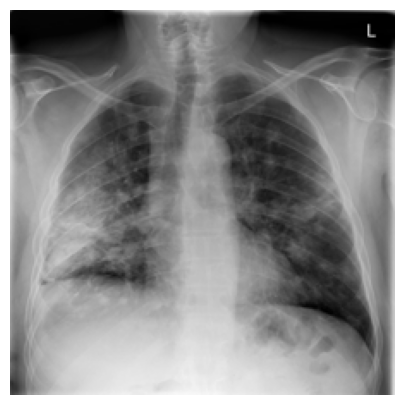

In [ ]:
test_image = load_xray(
    train_data.iloc[0]["patientId"]
)

print("Processed image shape:", test_image.shape)
print("Minimum pixel value:", test_image.min())
print("Maximum pixel value:", test_image.max())

plt.figure(figsize=(5, 5))
plt.imshow(test_image)
plt.axis("off")
plt.show()

In [ ]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32

def create_dataset(df):
    images = []
    labels_list = []

    for _, row in df.iterrows():
        image = load_xray(row["patientId"])

        # Convert to float and scale to 0–1
        image = image.astype(np.float32) / 255.0

        images.append(image)
        labels_list.append(row["Target"])

    images = np.array(images, dtype=np.float32)
    labels_list = np.array(labels_list, dtype=np.float32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (images, labels_list)
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [ ]:
train_dataset = create_dataset(train_data)
val_dataset = create_dataset(val_data)

print("TensorFlow datasets created successfully.")

NameError: name 'create_dataset' is not defined

In [ ]:
import os

print(os.path.exists("/content/rsna_data"))
print(os.listdir("/content/rsna_data") if os.path.exists("/content/rsna_data") else "Dataset folder not found")

True
['GCP Credits Request Link - RSNA.txt', 'stage_2_sample_submission.csv', 'stage_2_detailed_class_info.csv', 'stage_2_train_images', 'stage_2_test_images', 'stage_2_train_labels.csv']


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Paths
DATA_DIR = "/content/rsna_data"
IMAGE_FOLDER = os.path.join(DATA_DIR, "stage_2_train_images")

# Load labels
labels = pd.read_csv(
    os.path.join(DATA_DIR, "stage_2_train_labels.csv")
)

# One label per X-ray
image_labels = (
    labels.groupby("patientId")["Target"]
    .max()
    .reset_index()
)

# Separate classes
normal = image_labels[image_labels["Target"] == 0]
pneumonia = image_labels[image_labels["Target"] == 1]

# Balance classes
normal_sample = normal.sample(
    n=len(pneumonia),
    random_state=42
)

balanced_data = pd.concat([
    normal_sample,
    pneumonia
])

balanced_data = balanced_data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Train/validation split
train_data, val_data = train_test_split(
    balanced_data,
    test_size=0.2,
    random_state=42,
    stratify=balanced_data["Target"]
)

print("Total:", len(balanced_data))
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("\nTraining classes:")
print(train_data["Target"].value_counts())
print("\nValidation classes:")
print(val_data["Target"].value_counts())

Total: 12024
Training: 9619
Validation: 2405

Training classes:
Target
1    4810
0    4809
Name: count, dtype: int64

Validation classes:
Target
0    1203
1    1202
Name: count, dtype: int64


In [ ]:
import tensorflow as tf
import numpy as np
import pydicom
import os

IMAGE_FOLDER = "/content/rsna_data/stage_2_train_images"

IMG_SIZE = 224
BATCH_SIZE = 16

def load_image_for_model(patient_id):
    path = os.path.join(
        IMAGE_FOLDER,
        patient_id + ".dcm"
    )

    dicom = pydicom.dcmread(path)
    image = dicom.pixel_array.astype(np.float32)

    # Normalize
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    # Resize
    image = tf.image.resize(
        image[..., np.newaxis],
        [IMG_SIZE, IMG_SIZE]
    )

    # Grayscale -> RGB
    image = tf.image.grayscale_to_rgb(image)

    return image.numpy().astype(np.float32)


def data_generator(df):
    while True:
        # Shuffle rows every epoch
        df = df.sample(frac=1).reset_index(drop=True)

        for start in range(0, len(df), BATCH_SIZE):

            batch = df.iloc[start:start + BATCH_SIZE]

            images = []
            labels_batch = []

            for _, row in batch.iterrows():

                image = load_image_for_model(
                    row["patientId"]
                )

                images.append(image)
                labels_batch.append(
                    float(row["Target"])
                )

            yield (
                np.array(images, dtype=np.float32),
                np.array(labels_batch, dtype=np.float32)
            )

In [ ]:
train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(train_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, IMG_SIZE, IMG_SIZE, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(val_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, IMG_SIZE, IMG_SIZE, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)


In [ ]:
images, batch_labels = next(iter(train_dataset))

print("Batch image shape:", images.shape)
print("Batch labels shape:", batch_labels.shape)
print("Labels:", batch_labels.numpy())

Batch image shape: (16, 224, 224, 3)
Batch labels shape: (16,)
Labels: [0. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 1. 1. 0. 1.]


In [ ]:
import tensorflow as tf
from tensorflow import keras

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers initially
base_model.trainable = False

print("EfficientNetB0 loaded successfully.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0 loaded successfully.


In [ ]:
model = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
steps_per_epoch = len(train_data) // BATCH_SIZE
validation_steps = len(val_data) // BATCH_SIZE

print("Steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)

history = model.fit(
    train_dataset,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_dataset,
    validation_steps=validation_steps,
    epochs=3
)

Steps per epoch: 601
Validation steps: 150
Epoch 1/3


KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import numpy as np
import pydicom
import os

IMAGE_FOLDER = "/content/rsna_data/stage_2_train_images"

IMG_SIZE = 224
BATCH_SIZE = 16


def load_image_for_model(patient_id):
    path = os.path.join(
        IMAGE_FOLDER,
        patient_id + ".dcm"
    )

    dicom = pydicom.dcmread(path)

    image = dicom.pixel_array.astype(np.float32)

    # Normalize the original DICOM image
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    # Convert back to 0–255
    image *= 255.0

    # Resize
    image = tf.image.resize(
        image[..., np.newaxis],
        [IMG_SIZE, IMG_SIZE]
    )

    # Convert grayscale → RGB
    image = tf.image.grayscale_to_rgb(image)

    return image.numpy().astype(np.float32)


def data_generator(df):
    while True:

        shuffled_df = df.sample(
            frac=1,
            random_state=None
        ).reset_index(drop=True)

        for start in range(
            0,
            len(shuffled_df),
            BATCH_SIZE
        ):

            batch = shuffled_df.iloc[
                start:start + BATCH_SIZE
            ]

            images = []
            labels_batch = []

            for _, row in batch.iterrows():

                image = load_image_for_model(
                    row["patientId"]
                )

                images.append(image)

                labels_batch.append(
                    float(row["Target"])
                )

            yield (
                np.array(
                    images,
                    dtype=np.float32
                ),
                np.array(
                    labels_batch,
                    dtype=np.float32
                )
            )

In [ ]:
train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(train_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(val_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

print("Datasets recreated successfully.")

Datasets recreated successfully.


In [ ]:
images, batch_labels = next(iter(train_dataset))

print("Shape:", images.shape)
print("Minimum:", images.numpy().min())
print("Maximum:", images.numpy().max())
print("Labels:", batch_labels.numpy())

Shape: (16, 224, 224, 3)
Minimum: 0.0
Maximum: 255.0
Labels: [0. 0. 1. 0. 1. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 1.]


In [ ]:
from tensorflow import keras
import tensorflow as tf

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

print("Fresh EfficientNet model ready.")

Fresh EfficientNet model ready.


In [ ]:
steps_per_epoch = len(train_data) // BATCH_SIZE
validation_steps = len(val_data) // BATCH_SIZE

print("Steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)

history = model.fit(
    train_dataset,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_dataset,
    validation_steps=validation_steps,
    epochs=2
)

Steps per epoch: 601
Validation steps: 150
Epoch 1/2
601/601 ━━━━━━━━━━━━━━━━━━━━ 1262s 2s/step - accuracy: 0.6589 - auc: 0.7119 - loss: 0.6242 - val_accuracy: 0.7342 - val_auc: 0.7751 - val_loss: 0.5726
Epoch 2/2
601/601 ━━━━━━━━━━━━━━━━━━━━ 1234s 2s/step - accuracy: 0.7133 - auc: 0.7661 - loss: 0.5793 - val_accuracy: 0.7396 - val_auc: 0.7888 - val_loss: 0.5565


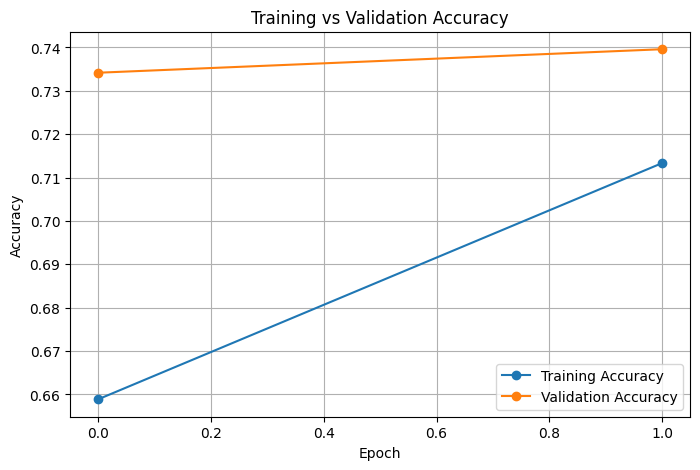

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

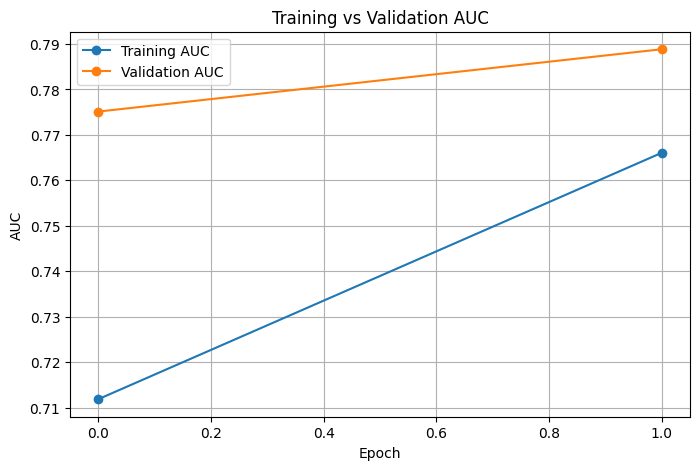

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["auc"],
    marker="o",
    label="Training AUC"
)

plt.plot(
    history.history["val_auc"],
    marker="o",
    label="Validation AUC"
)

plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Training vs Validation AUC")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
model.save(
    "/content/pneumonia_efficientnet.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [ ]:
import os

model_path = "/content/pneumonia_efficientnet.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print(
        "Model size:",
        round(os.path.getsize(model_path) / (1024**2), 2),
        "MB"
    )

Model exists: True
Model size: 16.27 MB


In [ ]:
def validation_generator(df):
    for start in range(0, len(df), BATCH_SIZE):

        batch = df.iloc[start:start + BATCH_SIZE]

        images = []
        labels_batch = []

        for _, row in batch.iterrows():

            image = load_image_for_model(
                row["patientId"]
            )

            images.append(image)

            labels_batch.append(
                float(row["Target"])
            )

        yield (
            np.array(images, dtype=np.float32),
            np.array(labels_batch, dtype=np.float32)
        )

In [ ]:
validation_dataset = tf.data.Dataset.from_generator(
    lambda: validation_generator(val_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

print("Fixed validation dataset ready.")

Fixed validation dataset ready.


In [ ]:
y_true = []
y_probability = []

for images_batch, labels_batch in validation_dataset:

    predictions = model.predict(
        images_batch,
        verbose=0
    ).flatten()

    y_probability.extend(
        predictions.tolist()
    )

    y_true.extend(
        labels_batch.numpy().tolist()
    )

y_true = np.array(y_true)
y_probability = np.array(y_probability)

print("Number of validation images:", len(y_true))
print("Number of predictions:", len(y_probability))

Number of validation images: 2405
Number of predictions: 2405


In [ ]:
y_pred = (y_probability >= 0.5).astype(int)

print("First 20 predictions:")
print(y_pred[:20])

print("\nFirst 20 actual labels:")
print(y_true[:20].astype(int))

First 20 predictions:
[1 0 1 1 0 0 0 1 1 1 0 0 1 1 0 1 0 1 1 0]

First 20 actual labels:
[1 0 0 0 1 0 0 1 0 0 0 0 1 1 1 0 0 0 1 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred
)

recall = recall_score(
    y_true,
    y_pred
)

f1 = f1_score(
    y_true,
    y_pred
)

auc = roc_auc_score(
    y_true,
    y_probability
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(auc, 4))

Accuracy : 0.7401
Precision: 0.7472
Recall   : 0.7255
F1 Score : 0.7362
ROC-AUC  : 0.7894


In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[908 295]
 [330 872]]


In [ ]:
TN, FP, FN, TP = cm.ravel()

specificity = TN / (TN + FP)

print("True Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives :", TP)

print(
    "\nSpecificity:",
    round(specificity, 4)
)

True Negatives : 908
False Positives: 295
False Negatives: 330
True Positives : 872

Specificity: 0.7548


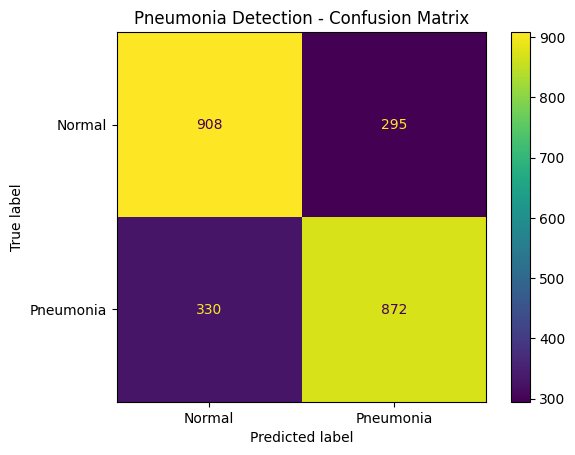

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot()

plt.title("Pneumonia Detection - Confusion Matrix")
plt.show()

In [ ]:
def predict_xray(patient_id):

    # Load and preprocess image
    image = load_image_for_model(patient_id)

    # Add batch dimension
    input_image = np.expand_dims(image, axis=0)

    # Predict
    probability = model.predict(
        input_image,
        verbose=0
    )[0][0]

    # Classification
    if probability >= 0.5:
        prediction = "PNEUMONIA"
        confidence = probability * 100
    else:
        prediction = "NORMAL"
        confidence = (1 - probability) * 100

    # Display image
    plt.figure(figsize=(6, 6))
    plt.imshow(image.astype(np.uint8))
    plt.axis("off")
    plt.title(
        f"{prediction}\nConfidence: {confidence:.2f}%"
    )
    plt.show()

    print("Prediction:", prediction)
    print(f"Confidence: {confidence:.2f}%")

    return prediction, confidence

In [ ]:
test_patient = val_data.iloc[0]["patientId"]

predict_xray(test_patient)

NameError: name 'val_data' is not defined

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/rsna_data"

# Load labels again
labels = pd.read_csv(
    f"{DATA_DIR}/stage_2_train_labels.csv"
)

# One label per X-ray
image_labels = (
    labels.groupby("patientId")["Target"]
    .max()
    .reset_index()
)

# Balance the dataset
normal = image_labels[image_labels["Target"] == 0]
pneumonia = image_labels[image_labels["Target"] == 1]

normal_sample = normal.sample(
    n=len(pneumonia),
    random_state=42
)

balanced_data = pd.concat([
    normal_sample,
    pneumonia
]).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Recreate exactly the same train/validation split
train_data, val_data = train_test_split(
    balanced_data,
    test_size=0.2,
    random_state=42,
    stratify=balanced_data["Target"]
)

print("Training:", len(train_data))
print("Validation:", len(val_data))

FileNotFoundError: [Errno 2] No such file or directory: '/content/rsna_data/stage_2_train_labels.csv'

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
!kaggle competitions list

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [ ]:
!kaggle competitions list

ref                                                                           deadline             category         reward  teamCount  userHasEntered  
----------------------------------------------------------------------------  -------------------  --------  -------------  ---------  --------------  
https://www.kaggle.com/competitions/passenger-screening-algorithm-challenge   2017-12-15 23:59:00  Featured  1,500,000 Usd        518           False  
https://www.kaggle.com/competitions/zillow-prize-1                            2018-01-10 15:59:00  Featured  1,200,000 Usd       3770           False  
https://www.kaggle.com/competitions/data-science-bowl-2017                    2017-04-12 23:59:00  Featured  1,000,000 Usd       1972           False  
https://www.kaggle.com/competitions/vesuvius-challenge-ink-detection          2023-06-14 23:59:00  Featured  1,000,000 Usd       1249           False  
https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3                  2026-11-02

In [ ]:
!kaggle competitions download -c rsna-pneumonia-detection-challenge

100% 3.66G/3.66G [00:37<00:00, 104MB/s]



In [ ]:
!unzip -q /content/rsna-pneumonia-detection-challenge.zip -d /content/rsna_data

In [ ]:
import os

print(os.listdir("/content/rsna_data"))

['GCP Credits Request Link - RSNA.txt', 'stage_2_sample_submission.csv', 'stage_2_detailed_class_info.csv', 'stage_2_train_images', 'stage_2_test_images', 'stage_2_train_labels.csv']


In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

print("Searching Google Drive for the model...")

found = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "pneumonia_efficientnet.keras":
            found.append(os.path.join(root, file))

if found:
    print("\nFOUND:")
    for path in found:
        print(path)
else:
    print("\nModel file was not found in Google Drive.")

Mounted at /content/drive
Searching Google Drive for the model...

Model file was not found in Google Drive.


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/rsna_data"
IMAGE_FOLDER = "/content/rsna_data/stage_2_train_images"

# Load labels
labels = pd.read_csv(
    f"{DATA_DIR}/stage_2_train_labels.csv"
)

# One label per X-ray
image_labels = (
    labels.groupby("patientId")["Target"]
    .max()
    .reset_index()
)

# Separate classes
normal = image_labels[image_labels["Target"] == 0]
pneumonia = image_labels[image_labels["Target"] == 1]

# Balance the classes
normal_sample = normal.sample(
    n=len(pneumonia),
    random_state=42
)

balanced_data = pd.concat([
    normal_sample,
    pneumonia
])

balanced_data = balanced_data.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Same 80/20 split as before
train_data, val_data = train_test_split(
    balanced_data,
    test_size=0.2,
    random_state=42,
    stratify=balanced_data["Target"]
)

print("Total:", len(balanced_data))
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("\nTraining classes:")
print(train_data["Target"].value_counts())
print("\nValidation classes:")
print(val_data["Target"].value_counts())

Total: 12024
Training: 9619
Validation: 2405

Training classes:
Target
1    4810
0    4809
Name: count, dtype: int64

Validation classes:
Target
0    1203
1    1202
Name: count, dtype: int64


In [ ]:
import tensorflow as tf
import numpy as np
import pydicom
import os

IMAGE_FOLDER = "/content/rsna_data/stage_2_train_images"

IMG_SIZE = 224
BATCH_SIZE = 16


def load_image_for_model(patient_id):
    path = os.path.join(
        IMAGE_FOLDER,
        patient_id + ".dcm"
    )

    dicom = pydicom.dcmread(path)

    image = dicom.pixel_array.astype(np.float32)

    # Normalize the DICOM image
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    # Convert to 0–255
    image *= 255.0

    # Resize
    image = tf.image.resize(
        image[..., np.newaxis],
        [IMG_SIZE, IMG_SIZE]
    )

    # Grayscale → RGB
    image = tf.image.grayscale_to_rgb(image)

    return image.numpy().astype(np.float32)


def data_generator(df):
    while True:

        shuffled_df = df.sample(
            frac=1
        ).reset_index(drop=True)

        for start in range(
            0,
            len(shuffled_df),
            BATCH_SIZE
        ):

            batch = shuffled_df.iloc[
                start:start + BATCH_SIZE
            ]

            images = []
            labels_batch = []

            for _, row in batch.iterrows():

                image = load_image_for_model(
                    row["patientId"]
                )

                images.append(image)

                labels_batch.append(
                    float(row["Target"])
                )

            yield (
                np.array(images, dtype=np.float32),
                np.array(labels_batch, dtype=np.float32)
            )

ModuleNotFoundError: No module named 'pydicom'

In [ ]:
!pip install -q pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 21.4 MB/s eta 0:00:00


In [ ]:
import tensorflow as tf
import numpy as np
import pydicom
import os

In [ ]:
train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(train_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(val_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

print("Datasets created successfully.")

Datasets created successfully.


In [ ]:
images, batch_labels = next(iter(train_dataset))

print("Batch image shape:", images.shape)
print("Batch labels shape:", batch_labels.shape)
print("Minimum pixel:", images.numpy().min())
print("Maximum pixel:", images.numpy().max())
print("Labels:", batch_labels.numpy())

UnknownError: {{function_node __wrapped__IteratorGetNext_output_types_2_device_/job:localhost/replica:0/task:0/device:CPU:0}} NameError: name 'data_generator' is not defined
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/data/ops/dataset_ops.py", line 865, in get_iterator
    return self._iterators[iterator_id]
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^

KeyError: np.int64(0)


During handling of the above exception, another exception occurred:


Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/ops/script_ops.py", line 269, in __call__
    ret = func(*args)

  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/autograph/impl/api.py", line 643, in wrapper
    return func(*args, **kwargs)

  File "/usr/local/lib/python3.13/dist-packages/tensorflow/python/data/ops/from_generator_op.py", line 198, in generator_py_func
    values = next(generator_state.get_iterator(iterator_

In [ ]:
import tensorflow as tf
import numpy as np
import pydicom
import os

IMAGE_FOLDER = "/content/rsna_data/stage_2_train_images"

IMG_SIZE = 224
BATCH_SIZE = 16


def load_image_for_model(patient_id):
    path = os.path.join(
        IMAGE_FOLDER,
        patient_id + ".dcm"
    )

    dicom = pydicom.dcmread(path)

    image = dicom.pixel_array.astype(np.float32)

    # Normalize
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    # Convert to 0–255
    image *= 255.0

    # Resize
    image = tf.image.resize(
        image[..., np.newaxis],
        [IMG_SIZE, IMG_SIZE]
    )

    # Grayscale → RGB
    image = tf.image.grayscale_to_rgb(image)

    return image.numpy().astype(np.float32)


def data_generator(df):
    while True:

        shuffled_df = df.sample(
            frac=1
        ).reset_index(drop=True)

        for start in range(
            0,
            len(shuffled_df),
            BATCH_SIZE
        ):

            batch = shuffled_df.iloc[
                start:start + BATCH_SIZE
            ]

            images = []
            labels_batch = []

            for _, row in batch.iterrows():

                image = load_image_for_model(
                    row["patientId"]
                )

                images.append(image)

                labels_batch.append(
                    float(row["Target"])
                )

            yield (
                np.array(images, dtype=np.float32),
                np.array(labels_batch, dtype=np.float32)
            )

print("Image loader and data generator are ready.")

Image loader and data generator are ready.


In [ ]:
train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(train_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(val_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

print("Datasets created successfully.")

Datasets created successfully.


In [ ]:
images, batch_labels = next(iter(train_dataset))

print("Batch image shape:", images.shape)
print("Batch labels shape:", batch_labels.shape)
print("Minimum pixel:", images.numpy().min())
print("Maximum pixel:", images.numpy().max())
print("Labels:", batch_labels.numpy())

Batch image shape: (16, 224, 224, 3)
Batch labels shape: (16,)
Minimum pixel: 0.0
Maximum pixel: 255.0
Labels: [1. 1. 1. 0. 1. 0. 1. 1. 0. 1. 0. 1. 0. 1. 1. 0.]


In [ ]:
import tensorflow as tf
from tensorflow import keras

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

model = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(
        1,
        activation="sigmoid"
    )
])

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc")
    ]
)

print("EfficientNet-B0 model ready.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNet-B0 model ready.


In [ ]:
steps_per_epoch = len(train_data) // BATCH_SIZE
validation_steps = len(val_data) // BATCH_SIZE

print("Steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)

history = model.fit(
    train_dataset,
    steps_per_epoch=steps_per_epoch,
    validation_data=val_dataset,
    validation_steps=validation_steps,
    epochs=2
)

Steps per epoch: 601
Validation steps: 150
Epoch 1/2
601/601 ━━━━━━━━━━━━━━━━━━━━ 1299s 2s/step - accuracy: 0.6456 - auc: 0.6956 - loss: 0.6346 - val_accuracy: 0.7292 - val_auc: 0.7793 - val_loss: 0.5680
Epoch 2/2
601/601 ━━━━━━━━━━━━━━━━━━━━ 1288s 2s/step - accuracy: 0.7073 - auc: 0.7631 - loss: 0.5817 - val_accuracy: 0.7408 - val_auc: 0.7929 - val_loss: 0.5507


In [ ]:
model_path = "/content/drive/MyDrive/pneumonia_efficientnet.keras"

model.save(model_path)

print("MODEL SAVED TO GOOGLE DRIVE!")
print(model_path)

MODEL SAVED TO GOOGLE DRIVE!
/content/drive/MyDrive/pneumonia_efficientnet.keras


In [ ]:
import os

model_path = "/content/drive/MyDrive/pneumonia_efficientnet.keras"

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print("Model size:", round(size_mb, 2), "MB")


Model exists: True
Model size: 16.27 MB


In [ ]:
def validation_generator(df):
    for start in range(0, len(df), BATCH_SIZE):

        batch = df.iloc[start:start + BATCH_SIZE]

        images = []
        labels_batch = []

        for _, row in batch.iterrows():

            image = load_image_for_model(
                row["patientId"]
            )

            images.append(image)

            labels_batch.append(
                float(row["Target"])
            )

        yield (
            np.array(images, dtype=np.float32),
            np.array(labels_batch, dtype=np.float32)
        )

print("Validation generator ready.")

Validation generator ready.


In [ ]:
y_true = []
y_probability = []

validation_dataset = tf.data.Dataset.from_generator(
    lambda: validation_generator(val_data),
    output_signature=(
        tf.TensorSpec(
            shape=(None, 224, 224, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(None,),
            dtype=tf.float32
        )
    )
)

for images_batch, labels_batch in validation_dataset:

    predictions = model.predict(
        images_batch,
        verbose=0
    ).flatten()

    y_probability.extend(
        predictions.tolist()
    )

    y_true.extend(
        labels_batch.numpy().tolist()
    )

y_true = np.array(y_true)
y_probability = np.array(y_probability)

print("Validation images:", len(y_true))
print("Predictions:", len(y_probability))

Validation images: 2405
Predictions: 2405


In [ ]:
y_pred = (y_probability >= 0.5).astype(int)

print("First 20 predictions:")
print(y_pred[:20])

print("\nFirst 20 actual labels:")
print(y_true[:20].astype(int))

First 20 predictions:
[1 0 1 1 0 0 0 1 1 1 0 1 1 1 0 1 0 1 1 0]

First 20 actual labels:
[1 0 0 0 1 0 0 1 0 0 0 0 1 1 1 0 0 0 1 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred
)

recall = recall_score(
    y_true,
    y_pred
)

f1 = f1_score(
    y_true,
    y_pred
)

auc = roc_auc_score(
    y_true,
    y_probability
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(auc, 4))

Accuracy : 0.741
Precision: 0.7419
Recall   : 0.7388
F1 Score : 0.7403
ROC-AUC  : 0.793


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[894 309]
 [314 888]]


In [ ]:
TN, FP, FN, TP = cm.ravel()

specificity = TN / (TN + FP)

print("True Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives :", TP)

print(
    "\nSpecificity:",
    round(specificity, 4)
)

True Negatives : 894
False Positives: 309
False Negatives: 314
True Positives : 888

Specificity: 0.7431


In [ ]:
TN, FP, FN, TP = cm.ravel()

specificity = TN / (TN + FP)

print("True Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives :", TP)

print(
    "\nSpecificity:",
    round(specificity, 4)
)

True Negatives : 894
False Positives: 309
False Negatives: 314
True Positives : 888

Specificity: 0.7431


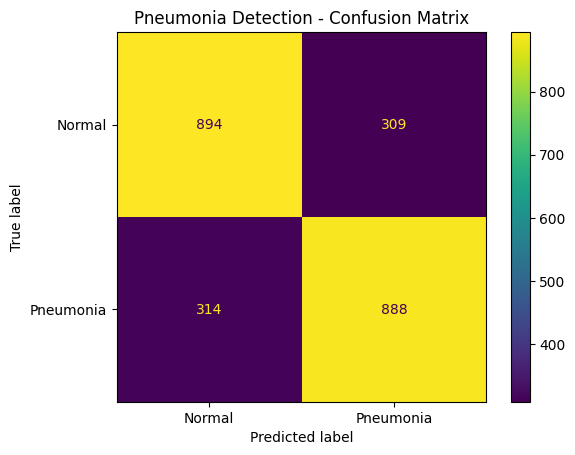

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Pneumonia"]
)

disp.plot()

plt.title("Pneumonia Detection - Confusion Matrix")
plt.show()

In [ ]:
def predict_xray(patient_id):

    # Load image
    image = load_image_for_model(patient_id)

    # Add batch dimension
    input_image = np.expand_dims(
        image,
        axis=0
    )

    # Model prediction
    probability = model.predict(
        input_image,
        verbose=0
    )[0][0]

    # Convert probability to result
    if probability >= 0.5:
        prediction = "PNEUMONIA"
        confidence = probability * 100
    else:
        prediction = "NORMAL"
        confidence = (1 - probability) * 100

    # Display image
    plt.figure(figsize=(6, 6))
    plt.imshow(
        image.astype(np.uint8)
    )
    plt.axis("off")

    plt.title(
        f"{prediction}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.show()

    print("Prediction:", prediction)
    print(f"Confidence: {confidence:.2f}%")

    return prediction, confidence

print("Prediction function ready.")

Prediction function ready.


Patient ID: fa8ea2ce-097a-4e42-8f9b-c3d0603484f1
Actual label: 1


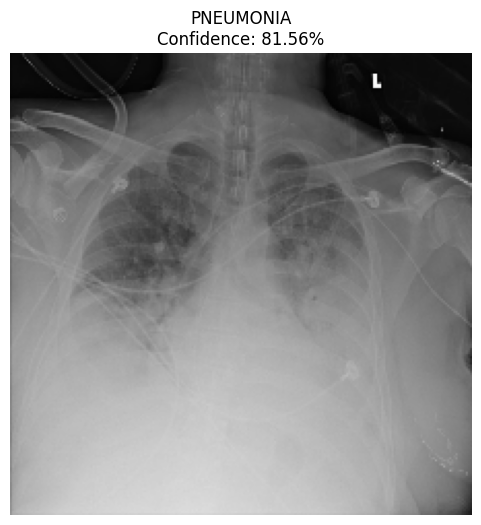

Prediction: PNEUMONIA
Confidence: 81.56%


('PNEUMONIA', np.float32(81.55888))

In [ ]:
test_patient = val_data.iloc[0]["patientId"]

print("Patient ID:", test_patient)
print("Actual label:", val_data.iloc[0]["Target"])

predict_xray(test_patient)

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


def predict_uploaded_xray(image):

    # Check that an image was uploaded
    if image is None:
        return None, "Please upload a chest X-ray.", ""

    # Convert uploaded image to grayscale
    image = np.array(image)

    if image.ndim == 3:
        image = tf.image.rgb_to_grayscale(image).numpy().squeeze()

    image = image.astype(np.float32)

    # Normalize
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    # Convert to 0–255
    image *= 255.0

    # Resize to model input size
    image = tf.image.resize(
        image[..., np.newaxis],
        [224, 224]
    )

    # Convert grayscale → RGB
    image = tf.image.grayscale_to_rgb(image)

    image = image.numpy().astype(np.float32)

    # Add batch dimension
    input_image = np.expand_dims(
        image,
        axis=0
    )

    # Model prediction
    probability = model.predict(
        input_image,
        verbose=0
    )[0][0]

    # Classification
    if probability >= 0.5:
        prediction = "PNEUMONIA"
        confidence = probability * 100
    else:
        prediction = "NORMAL"
        confidence = (1 - probability) * 100

    result = f"{prediction}"
    confidence_text = f"{confidence:.2f}%"

    return (
        image.astype(np.uint8),
        result,
        confidence_text
    )


demo = gr.Interface(
    fn=predict_uploaded_xray,
    inputs=gr.Image(
        type="numpy",
        label="Upload Chest X-ray"
    ),
    outputs=[
        gr.Image(label="Processed X-ray"),
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Confidence")
    ],
    title="🫁 Pneumonia Detection Prototype",
    description=(
        "Upload a chest X-ray to obtain an AI-generated "
        "Normal/Pneumonia classification."
    ),
    article=(
        "⚠️ Research prototype only. "
        "This system is not a medical device and "
        "must not be used for clinical diagnosis."
    )
)

print("Gradio interface created successfully.")

Gradio interface created successfully.


In [ ]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a375535a4a0b4a4cca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
gradio_code = '''
# Pneumonia Detection Prototype
# Gradio interface code is in the notebook above.
'''

with open("/content/drive/MyDrive/pneumonia_gradio_backup.py", "w") as f:
    f.write(gradio_code)

print("Gradio backup created in Google Drive.")

Gradio backup created in Google Drive.


In [ ]:
# Find the last 4D convolutional feature layer
for layer in reversed(base_model.layers):
    try:
        if len(layer.output.shape) == 4:
            print("Grad-CAM layer:", layer.name)
            print("Output shape:", layer.output.shape)
            break
    except:
        pass

Grad-CAM layer: top_activation
Output shape: (None, 7, 7, 1280)


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    # Create a model that outputs:
    # 1. convolutional feature maps
    # 2. final prediction
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer("efficientnetb0")
                 .get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array
        )

        # Pneumonia probability
        class_channel = predictions[:, 0]

    # Gradients of prediction with respect to feature maps
    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    # Average gradients over spatial dimensions
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weight feature maps by gradients
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    # Keep positive activations
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize to 0–1
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy()


print("Grad-CAM function created successfully.")

Grad-CAM function created successfully.


In [ ]:
# Use the same validation X-ray
test_patient = val_data.iloc[0]["patientId"]

# Load and preprocess the X-ray
image = load_image_for_model(test_patient)

# Add batch dimension
input_image = np.expand_dims(
    image,
    axis=0
)

# Generate Grad-CAM heatmap
heatmap = make_gradcam_heatmap(
    input_image,
    model,
    "top_activation"
)

print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

AttributeError: The layer sequential has never been called and thus has no defined output.

In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    # Get EfficientNet base model
    efficientnet = model.layers[0]

    # Create a model that directly uses the EfficientNet
    grad_model = tf.keras.models.Model(
        inputs=efficientnet.input,
        outputs=[
            efficientnet.get_layer(
                last_conv_layer_name
            ).output,
            efficientnet.output
        ]
    )

    # Get gradients
    with tf.GradientTape() as tape:

        conv_outputs, features = grad_model(
            img_array
        )

        # Pass EfficientNet features through the
        # remaining classification layers
        x = features

        for layer in model.layers[1:]:
            x = layer(x)

        prediction = x[:, 0]

    # Calculate gradients
    grads = tape.gradient(
        prediction,
        conv_outputs
    )

    # Average gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weight feature maps
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    # Keep positive values
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_value = tf.reduce_max(heatmap)

    if max_value > 0:
        heatmap = heatmap / max_value

    return heatmap.numpy()


print("Updated Grad-CAM function ready.")

Updated Grad-CAM function ready.


In [ ]:
test_patient = val_data.iloc[0]["patientId"]

image = load_image_for_model(test_patient)

input_image = np.expand_dims(
    image,
    axis=0
)

heatmap = make_gradcam_heatmap(
    input_image,
    model,
    "top_activation"
)

print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())

Heatmap shape: (7, 7)
Heatmap minimum: 0.0
Heatmap maximum: 1.0


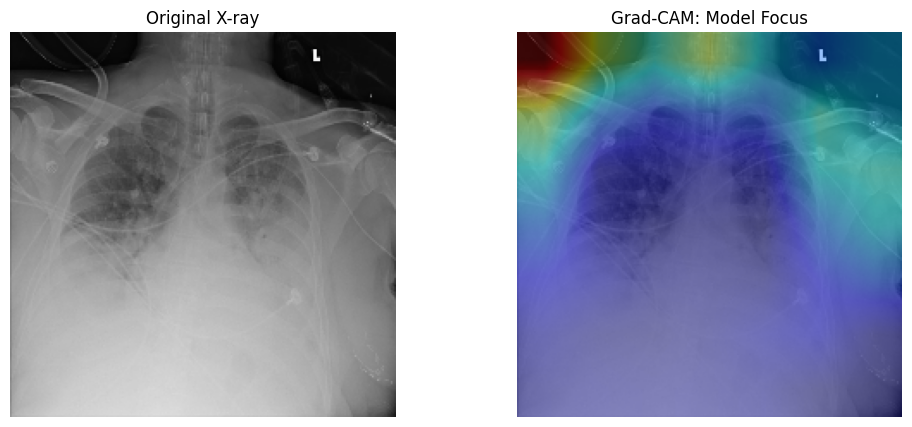

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Original X-ray
original = image.astype(np.uint8)

# Resize heatmap to X-ray size
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

# Convert heatmap to color
heatmap_uint8 = np.uint8(
    255 * heatmap_resized
)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

# Convert BGR → RGB
heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Overlay heatmap on X-ray
overlay = cv2.addWeighted(
    original,
    0.6,
    heatmap_color,
    0.4,
    0
)

# Display
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title("Grad-CAM: Model Focus")
plt.axis("off")

plt.show()

In [ ]:
def predict_with_gradcam(image):

    if image is None:
        return None, "Please upload a chest X-ray.", "", None

    # Convert uploaded image to numpy
    image = np.array(image)

    # RGB → grayscale
    if image.ndim == 3:
        image = tf.image.rgb_to_grayscale(
            image
        ).numpy().squeeze()

    image = image.astype(np.float32)

    # Normalize
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    image *= 255.0

    # Resize
    image = tf.image.resize(
        image[..., np.newaxis],
        [224, 224]
    )

    # Grayscale → RGB
    image = tf.image.grayscale_to_rgb(
        image
    )

    image = image.numpy().astype(np.float32)

    # Batch dimension
    input_image = np.expand_dims(
        image,
        axis=0
    )

    # Model prediction
    probability = model.predict(
        input_image,
        verbose=0
    )[0][0]

    # Classification
    if probability >= 0.5:
        prediction = "PNEUMONIA"
        confidence = probability * 100
    else:
        prediction = "NORMAL"
        confidence = (1 - probability) * 100

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        input_image,
        model,
        "top_activation"
    )

    # Resize heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224)
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Create overlay
    overlay = cv2.addWeighted(
        image.astype(np.uint8),
        0.6,
        heatmap_color,
        0.4,
        0
    )

    return (
        image.astype(np.uint8),
        prediction,
        f"{confidence:.2f}%",
        overlay
    )


print("Grad-CAM prediction function ready.")

Grad-CAM prediction function ready.


In [ ]:
import gradio as gr

demo_gradcam = gr.Interface(
    fn=predict_with_gradcam,

    inputs=gr.Image(
        type="numpy",
        label="Upload Chest X-ray"
    ),

    outputs=[
        gr.Image(
            label="Processed X-ray"
        ),
        gr.Textbox(
            label="Prediction"
        ),
        gr.Textbox(
            label="Confidence"
        ),
        gr.Image(
            label="Grad-CAM — Model Focus"
        )
    ],

    title="🫁 Pneumonia Detection Prototype",

    description=(
        "Upload a chest X-ray to obtain an "
        "AI-generated Normal/Pneumonia classification "
        "and an interpretability visualization."
    ),

    article=(
        "⚠️ Research prototype only. "
        "The prediction and Grad-CAM visualization are "
        "not a medical diagnosis and should not be used "
        "for clinical decision-making."
    )
)

print("Upgraded Gradio interface created successfully.")

Upgraded Gradio interface created successfully.


In [ ]:
demo_gradcam.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57df109ebcacc80e31.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
def predict_with_gradcam_v2(image):

    if image is None:
        return None, "Please upload a chest X-ray.", "", "", None

    # Convert uploaded image to numpy
    image = np.array(image)

    # RGB → grayscale
    if image.ndim == 3:
        image = tf.image.rgb_to_grayscale(
            image
        ).numpy().squeeze()

    image = image.astype(np.float32)

    # Normalize
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    image *= 255.0

    # Resize
    image = tf.image.resize(
        image[..., np.newaxis],
        [224, 224]
    )

    # Grayscale → RGB
    image = tf.image.grayscale_to_rgb(image)

    image = image.numpy().astype(np.float32)

    # Add batch dimension
    input_image = np.expand_dims(
        image,
        axis=0
    )

    # Get pneumonia probability
    pneumonia_probability = float(
        model.predict(
            input_image,
            verbose=0
        )[0][0]
    )

    # Calculate both probabilities
    normal_probability = 1.0 - pneumonia_probability

    # Classification threshold
    threshold = 0.5

    if pneumonia_probability >= threshold:
        prediction = "PNEUMONIA"
    else:
        prediction = "NORMAL"

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        input_image,
        model,
        "top_activation"
    )

    # Resize heatmap
    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224)
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    # Overlay
    overlay = cv2.addWeighted(
        image.astype(np.uint8),
        0.6,
        heatmap_color,
        0.4,
        0
    )

    return (
        image.astype(np.uint8),
        prediction,
        f"{normal_probability * 100:.2f}%",
        f"{pneumonia_probability * 100:.2f}%",
        overlay
    )


print("Updated prediction function ready.")

Updated prediction function ready.


In [ ]:
demo_final = gr.Interface(
    fn=predict_with_gradcam_v2,

    inputs=gr.Image(
        type="numpy",
        label="Upload Chest X-ray"
    ),

    outputs=[
        gr.Image(
            label="Processed X-ray"
        ),

        gr.Textbox(
            label="Prediction"
        ),

        gr.Textbox(
            label="Normal Probability"
        ),

        gr.Textbox(
            label="Pneumonia Probability"
        ),

        gr.Image(
            label="Grad-CAM — Model Focus"
        )
    ],

    title="🫁 Pneumonia Detection Prototype",

    description=(
        "AI-assisted chest X-ray classification using "
        "EfficientNet-B0 with Grad-CAM explainability."
    ),

    article=(
        "Decision threshold: 50% pneumonia probability. "
        "⚠️ Research prototype only — not a medical device "
        "and not intended for clinical diagnosis."
    )
)

print("Final Gradio interface created successfully.")

Final Gradio interface created successfully.


In [ ]:
demo_final.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://285c149866a16a40d4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

print("Threshold Analysis")
print("-" * 75)

for threshold in thresholds:

    predictions = (
        y_probability >= threshold
    ).astype(int)

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )

    print(
        f"Threshold: {threshold:.1f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold Analysis
---------------------------------------------------------------------------
Threshold: 0.3 | Accuracy: 0.6977 | Precision: 0.6423 | Recall: 0.8918 | F1: 0.7468
Threshold: 0.4 | Accuracy: 0.7289 | Precision: 0.6967 | Recall: 0.8103 | F1: 0.7492
Threshold: 0.5 | Accuracy: 0.7410 | Precision: 0.7419 | Recall: 0.7388 | F1: 0.7403
Threshold: 0.6 | Accuracy: 0.7189 | Precision: 0.7589 | Recall: 0.6414 | F1: 0.6952
Threshold: 0.7 | Accuracy: 0.6761 | Precision: 0.7839 | Recall: 0.4859 | F1: 0.5999


In [ ]:
from sklearn.metrics import confusion_matrix

threshold = 0.4

y_pred_04 = (y_probability >= threshold).astype(int)

cm_04 = confusion_matrix(
    y_true,
    y_pred_04
)

TN, FP, FN, TP = cm_04.ravel()

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

print("Confusion Matrix at threshold 0.4:")
print(cm_04)

print("\nTrue Negatives :", TN)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Positives :", TP)

print("\nSensitivity / Recall:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))

Confusion Matrix at threshold 0.4:
[[779 424]
 [228 974]]

True Negatives : 779
False Positives: 424
False Negatives: 228
True Positives : 974

Sensitivity / Recall: 0.8103
Specificity: 0.6475


In [ ]:
def predict_with_gradcam_final(image):

    if image is None:
        return None, "Please upload a chest X-ray.", "", "", "", None

    # Convert uploaded image to numpy
    image = np.array(image)

    # RGB → grayscale
    if image.ndim == 3:
        image = tf.image.rgb_to_grayscale(
            image
        ).numpy().squeeze()

    image = image.astype(np.float32)

    # Normalize
    image -= image.min()

    if image.max() > 0:
        image /= image.max()

    image *= 255.0

    # Resize
    image = tf.image.resize(
        image[..., np.newaxis],
        [224, 224]
    )

    # Grayscale → RGB
    image = tf.image.grayscale_to_rgb(image)

    image = image.numpy().astype(np.float32)

    # Add batch dimension
    input_image = np.expand_dims(
        image,
        axis=0
    )

    # Model prediction
    pneumonia_probability = float(
        model.predict(
            input_image,
            verbose=0
        )[0][0]
    )

    normal_probability = 1.0 - pneumonia_probability

    # FINAL PROTOTYPE THRESHOLD
    threshold = 0.4

    if pneumonia_probability >= threshold:
        prediction = "PNEUMONIA"
    else:
        prediction = "NORMAL"

    # Grad-CAM
    heatmap = make_gradcam_heatmap(
        input_image,
        model,
        "top_activation"
    )

    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224)
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        image.astype(np.uint8),
        0.6,
        heatmap_color,
        0.4,
        0
    )

    return (
        image.astype(np.uint8),
        prediction,
        f"{normal_probability * 100:.2f}%",
        f"{pneumonia_probability * 100:.2f}%",
        "40%",
        overlay
    )


print("Final prediction function ready.")

Final prediction function ready.


In [ ]:
import gradio as gr

print("Gradio imported successfully.")

Gradio imported successfully.


In [ ]:
import gradio as gr

demo_clean = gr.Interface(
    fn=predict_final,

    inputs=gr.Image(
        type="numpy",
        label="Upload Chest X-ray"
    ),

    outputs=[
        gr.Image(
            label="Processed X-ray"
        ),

        gr.Textbox(
            label="Prediction"
        ),

        gr.Textbox(
            label="Normal Probability"
        ),

        gr.Textbox(
            label="Pneumonia Probability"
        ),

        gr.Image(
            label="Grad-CAM — Model Focus"
        )
    ],

    title="🫁 Pneumonia Detection Prototype",

    description=(
        "AI-assisted chest X-ray classification using "
        "EfficientNet-B0 with Grad-CAM explainability."
    ),

    article=(
        "⚠️ Research prototype only — not a medical device "
        "and not intended for clinical diagnosis."
    )
)

print("Gradio interface updated successfully.")

Gradio interface updated successfully.


In [ ]:
demo_clean.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e49d97ab4d711c00dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import numpy as np

print("NumPy imported successfully.")

NumPy imported successfully.


In [ ]:
demo_clean.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e49d97ab4d711c00dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# IMPORT EVERYTHING REQUIRED
# ============================================

import os
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import gradio as gr

print("All required libraries imported successfully.")

All required libraries imported successfully.


In [ ]:
print("model:", "OK" if "model" in globals() else "MISSING")
print("make_gradcam_heatmap:", "OK" if "make_gradcam_heatmap" in globals() else "MISSING")
print("predict_final:", "OK" if "predict_final" in globals() else "MISSING")

model: MISSING
make_gradcam_heatmap: MISSING
predict_final: OK


In [ ]:
# ============================================
# RESTORE MODEL + GRAD-CAM
# ============================================

import os
import numpy as np
import tensorflow as tf
import cv2
import gradio as gr

# --------------------------------------------
# 1. Load saved model from Google Drive
# --------------------------------------------

model_path = "/content/drive/MyDrive/pneumonia_efficientnet.keras"

print("Checking saved model...")

if not os.path.exists(model_path):
    raise FileNotFoundError(
        "Model not found at: " + model_path
    )

model = tf.keras.models.load_model(model_path)

print("Model loaded successfully.")
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)


# --------------------------------------------
# 2. Find EfficientNet base model
# --------------------------------------------

base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break

if base_model is None:
    raise ValueError(
        "EfficientNet base model could not be found."
    )

print("Base model:", base_model.name)


# --------------------------------------------
# 3. Find Grad-CAM convolutional layer
# --------------------------------------------

gradcam_layer = None

for layer in reversed(base_model.layers):

    try:
        if len(layer.output.shape) == 4:
            gradcam_layer = layer
            break
    except:
        pass

if gradcam_layer is None:
    raise ValueError(
        "No suitable Grad-CAM layer found."
    )

print("Grad-CAM layer:", gradcam_layer.name)
print("Grad-CAM output:", gradcam_layer.output.shape)


# --------------------------------------------
# 4. Create Grad-CAM function
# --------------------------------------------

def make_gradcam_heatmap(
    img_array,
    model,
    layer_name=None
):

    # Find convolutional layer
    if layer_name is not None:
        conv_layer = base_model.get_layer(
            layer_name
        )
    else:
        conv_layer = gradcam_layer

    # Model producing:
    # convolutional activations + prediction
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array
        )

        # Pneumonia output
        loss = predictions[:, 0]

    # Gradients
    grads = tape.gradient(
        loss,
        conv_outputs
    )

    # Average gradients across spatial dimensions
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]

    # Weight feature maps
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    # Keep positive activations
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize 0–1
    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy()


print("Grad-CAM function restored successfully.")


# --------------------------------------------
# 5. Verify everything
# --------------------------------------------

print("\nFINAL CHECK")
print("model:", "OK" if "model" in globals() else "MISSING")
print(
    "make_gradcam_heatmap:",
    "OK" if "make_gradcam_heatmap" in globals()
    else "MISSING"
)
print(
    "predict_final:",
    "OK" if "predict_final" in globals()
    else "MISSING"
)

Checking saved model...


FileNotFoundError: Model not found at: /content/drive/MyDrive/pneumonia_efficientnet.keras

In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount("/content/drive")

print("\nSearching Google Drive for the saved model...")

found = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "pneumonia_efficientnet.keras":
            found.append(os.path.join(root, file))

if found:
    print("\nMODEL FOUND:")
    for path in found:
        print(path)
else:
    print("\nMODEL NOT FOUND anywhere in MyDrive.")

Mounted at /content/drive

Searching Google Drive for the saved model...

MODEL FOUND:
/content/drive/MyDrive/pneumonia_efficientnet.keras


In [ ]:
import tensorflow as tf

model_path = "/content/drive/MyDrive/pneumonia_efficientnet.keras"

model = tf.keras.models.load_model(model_path)

print("MODEL LOADED SUCCESSFULLY")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

MODEL LOADED SUCCESSFULLY
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
# ============================================
# RESTORE GRAD-CAM
# ============================================

# Find the EfficientNet base model
base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break

print("Base model:", base_model.name)


# Find the last 4D convolutional feature layer
gradcam_layer = None

for layer in reversed(base_model.layers):
    try:
        if len(layer.output.shape) == 4:
            gradcam_layer = layer
            break
    except:
        pass

print("Grad-CAM layer:", gradcam_layer.name)
print("Grad-CAM output shape:", gradcam_layer.output.shape)


# ============================================
# GRAD-CAM FUNCTION
# ============================================

def make_gradcam_heatmap(
    img_array,
    model,
    layer_name
):

    conv_layer = base_model.get_layer(
        layer_name
    )

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array
        )

        pneumonia_output = predictions[:, 0]

    grads = tape.gradient(
        pneumonia_output,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = (
        conv_outputs
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy()


print("Grad-CAM restored successfully.")

Base model: efficientnetb0
Grad-CAM layer: top_activation
Grad-CAM output shape: (None, 7, 7, 1280)
Grad-CAM restored successfully.


In [ ]:
# ============================================
# RESTORE GRAD-CAM
# ============================================

# Find the EfficientNet base model
base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break

print("Base model:", base_model.name)


# Find the last 4D convolutional feature layer
gradcam_layer = None

for layer in reversed(base_model.layers):
    try:
        if len(layer.output.shape) == 4:
            gradcam_layer = layer
            break
    except:
        pass

print("Grad-CAM layer:", gradcam_layer.name)
print("Grad-CAM output shape:", gradcam_layer.output.shape)


# ============================================
# GRAD-CAM FUNCTION
# ============================================

def make_gradcam_heatmap(
    img_array,
    model,
    layer_name
):

    conv_layer = base_model.get_layer(
        layer_name
    )

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array
        )

        pneumonia_output = predictions[:, 0]

    grads = tape.gradient(
        pneumonia_output,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = (
        conv_outputs
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:
        heatmap /= max_value

    return heatmap.numpy()


print("Grad-CAM restored successfully.")

Base model: efficientnetb0
Grad-CAM layer: top_activation
Grad-CAM output shape: (None, 7, 7, 1280)
Grad-CAM restored successfully.


In [ ]:
print("model:", "OK" if "model" in globals() else "MISSING")
print(
    "make_gradcam_heatmap:",
    "OK" if "make_gradcam_heatmap" in globals()
    else "MISSING"
)
print(
    "predict_final:",
    "OK" if "predict_final" in globals()
    else "MISSING"
)

model: OK
make_gradcam_heatmap: OK
predict_final: OK


In [ ]:
# Test using the first validation image

test_patient = val_data.iloc[0]["patientId"]

print("Testing patient:", test_patient)

test_image = load_image_for_model(test_patient)

result = predict_final(test_image)

print("\nPrediction test completed.")
print("Prediction:", result[1])
print("Normal probability:", result[2])
print("Pneumonia probability:", result[3])

NameError: name 'val_data' is not defined

In [ ]:
demo_clean.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e49d97ab4d711c00dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================
# FIX GRAD-CAM FOR RELOADED MODEL
# ============================================

import numpy as np
import tensorflow as tf
import cv2

# Force the loaded model to build/call once
dummy_input = tf.zeros((1, 224, 224, 3), dtype=tf.float32)
_ = model(dummy_input, training=False)

print("Model called successfully.")


# Find EfficientNet base model
base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break

if base_model is None:
    raise ValueError("EfficientNet base model not found.")

# Call the base model once
_ = base_model(dummy_input, training=False)

print("Base model:", base_model.name)


# Find last 4D convolutional layer
gradcam_layer = None

for layer in reversed(base_model.layers):

    try:
        output_shape = layer.output.shape

        if len(output_shape) == 4:
            gradcam_layer = layer
            break

    except:
        pass


if gradcam_layer is None:
    raise ValueError(
        "Could not find a suitable Grad-CAM layer."
    )

print("Grad-CAM layer:", gradcam_layer.name)
print(
    "Grad-CAM output:",
    gradcam_layer.output.shape
)


# ============================================
# CREATE FEATURE EXTRACTOR
# ============================================

feature_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=gradcam_layer.output
)


# ============================================
# GRAD-CAM FUNCTION
# ============================================

def make_gradcam_heatmap(
    img_array,
    model=None,
    layer_name=None
):

    with tf.GradientTape() as tape:

        # Get convolutional feature maps
        conv_outputs = feature_model(
            img_array,
            training=False
        )

        # Get final model prediction
        predictions = model(
            img_array,
            training=False
        )

        pneumonia_probability = predictions[:, 0]

    # Calculate gradients
    grads = tape.gradient(
        pneumonia_probability,
        conv_outputs
    )

    # Average gradients over height and width
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # First image in batch
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Weight feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # Keep positive activations
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:
        heatmap = heatmap / max_value

    return heatmap.numpy()


print("Grad-CAM fixed successfully.")

Model called successfully.
Base model: efficientnetb0
Grad-CAM layer: top_activation
Grad-CAM output: (None, 7, 7, 1280)
Grad-CAM fixed successfully.


In [ ]:
demo_clean.launch(share=True)


Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e49d97ab4d711c00dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================================
# FINAL GRAD-CAM FIX
# ============================================================

import numpy as np
import tensorflow as tf
import cv2

# Make sure the model has been called
dummy_input = tf.zeros(
    (1, 224, 224, 3),
    dtype=tf.float32
)

_ = model(dummy_input, training=False)


# ------------------------------------------------------------
# Find EfficientNet base model
# ------------------------------------------------------------

base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break

if base_model is None:
    raise ValueError("EfficientNet base model not found.")

print("Base model:", base_model.name)


# ------------------------------------------------------------
# Make sure base model is built
# ------------------------------------------------------------

_ = base_model(
    dummy_input,
    training=False
)


# ------------------------------------------------------------
# Find last 4D convolutional layer
# ------------------------------------------------------------

gradcam_layer = None

for layer in reversed(base_model.layers):

    try:
        if len(layer.output.shape) == 4:
            gradcam_layer = layer
            break
    except:
        pass

if gradcam_layer is None:
    raise ValueError(
        "No suitable Grad-CAM layer found."
    )

print("Grad-CAM layer:", gradcam_layer.name)
print(
    "Grad-CAM output:",
    gradcam_layer.output.shape
)


# ------------------------------------------------------------
# IMPORTANT:
# Create one connected model that returns:
# 1. convolutional activations
# 2. base model output
# ------------------------------------------------------------

gradcam_base_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        gradcam_layer.output,
        base_model.output
    ]
)


# ------------------------------------------------------------
# Identify layers AFTER EfficientNet
# ------------------------------------------------------------

base_index = model.layers.index(base_model)

head_layers = model.layers[
    base_index + 1:
]

print(
    "Classification head layers:",
    [layer.name for layer in head_layers]
)


# ------------------------------------------------------------
# FINAL GRAD-CAM FUNCTION
# ------------------------------------------------------------

def make_gradcam_heatmap(
    img_array,
    model=None,
    layer_name=None
):

    if model is None:
        model = globals()["model"]

    with tf.GradientTape() as tape:

        # Both values come from the SAME connected graph
        conv_outputs, base_output = gradcam_base_model(
            img_array,
            training=False
        )

        # Pass base output through classification head
        predictions = base_output

        for layer in head_layers:
            predictions = layer(
                predictions,
                training=False
            )

        pneumonia_probability = predictions[:, 0]

    # --------------------------------------------------------
    # Calculate gradients
    # --------------------------------------------------------

    grads = tape.gradient(
        pneumonia_probability,
        conv_outputs
    )

    # Safety check
    if grads is None:
        raise RuntimeError(
            "Gradients are None. Grad-CAM graph is not connected."
        )

    # --------------------------------------------------------
    # Average gradients across spatial dimensions
    # --------------------------------------------------------

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # --------------------------------------------------------
    # Weight feature maps
    # --------------------------------------------------------

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # Keep positive activations
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize 0–1
    max_value = tf.reduce_max(
        heatmap
    )

    if max_value > 0:
        heatmap = heatmap / max_value

    return heatmap.numpy()


print("\nFINAL GRAD-CAM READY.")

Base model: efficientnetb0
Grad-CAM layer: top_activation
Grad-CAM output: (None, 7, 7, 1280)
Classification head layers: ['global_average_pooling2d', 'dropout', 'dense']

FINAL GRAD-CAM READY.


In [ ]:
demo_clean = gr.Interface(
    fn=predict_final,
    inputs=gr.Image(
        type="numpy",
        label="Upload Chest X-ray"
    ),
    outputs=[
        gr.Image(label="Processed X-ray"),
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Normal Probability"),
        gr.Textbox(label="Pneumonia Probability"),
        gr.Image(label="Grad-CAM — Model Focus")
    ],
    title="🫁 Pneumonia Detection Prototype",
    description=(
        "AI-assisted chest X-ray classification using "
        "EfficientNet-B0 with Grad-CAM explainability."
    ),
    article=(
        "⚠️ Research prototype only — not a medical device "
        "and not intended for clinical diagnosis."
    )
)

demo_clean.launch(share=True)

NameError: name 'gr' is not defined

In [ ]:
# ============================================================
# 🫁 PNEUMONIA DETECTION — START HERE / RECOVERY CELL
# ============================================================

# 1. Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# 2. Imports
import os
import numpy as np
import tensorflow as tf
import cv2
import gradio as gr

print("Libraries loaded.")

# ============================================================
# 3. Load trained model
# ============================================================

MODEL_PATH = "/content/drive/MyDrive/pneumonia_efficientnet.keras"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        f"Model not found at:\n{MODEL_PATH}"
    )

model = tf.keras.models.load_model(MODEL_PATH)

# Call model once so all graph outputs are initialized
dummy_input = tf.zeros((1, 224, 224, 3), dtype=tf.float32)
_ = model(dummy_input, training=False)

print("Model loaded successfully.")
print("Input:", model.input_shape)
print("Output:", model.output_shape)

# ============================================================
# 4. Find EfficientNet base model
# ============================================================

base_model = None
base_index = None

for i, layer in enumerate(model.layers):
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        base_index = i
        break

if base_model is None:
    raise RuntimeError("EfficientNet base model could not be found.")

# Initialize base model
_ = base_model(dummy_input, training=False)

print("Base model:", base_model.name)

# ============================================================
# 5. Find Grad-CAM convolutional layer
# ============================================================

gradcam_layer = None

for layer in reversed(base_model.layers):
    try:
        shape = layer.output.shape
        if len(shape) == 4:
            gradcam_layer = layer
            break
    except:
        pass

if gradcam_layer is None:
    raise RuntimeError("No suitable Grad-CAM layer found.")

print("Grad-CAM layer:", gradcam_layer.name)
print("Grad-CAM output:", gradcam_layer.output.shape)

# ============================================================
# 6. Create connected Grad-CAM model
# ============================================================

gradcam_base_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        gradcam_layer.output,
        base_model.output
    ]
)

# Classification head after EfficientNet
head_layers = model.layers[base_index + 1:]

print(
    "Classification head:",
    [layer.name for layer in head_layers]
)

# ============================================================
# 7. Grad-CAM function
# ============================================================

def make_gradcam_heatmap(img_array):

    with tf.GradientTape() as tape:

        conv_outputs, base_output = gradcam_base_model(
            img_array,
            training=False
        )

        x = base_output

        for layer in head_layers:
            x = layer(x)

        pneumonia_output = x[:, 0]

    grads = tape.gradient(
        pneumonia_output,
        conv_outputs
    )

    if grads is None:
        raise RuntimeError(
            "Grad-CAM gradients are None."
        )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy()

# ============================================================
# 8. Final prediction function
# ============================================================

def predict_final(image):

    if image is None:
        return (
            None,
            "Please upload a chest X-ray.",
            "",
            "",
            None
        )

    try:

        image = np.array(image)

        # Remove alpha channel if present
        if image.ndim == 3 and image.shape[-1] == 4:
            image = image[:, :, :3]

        # Convert RGB to grayscale
        if image.ndim == 3 and image.shape[-1] == 3:
            image = tf.image.rgb_to_grayscale(
                image
            ).numpy().squeeze()

        image = image.astype(np.float32)

        # Normalize image
        image -= image.min()

        if image.max() > 0:
            image /= image.max()

        image *= 255.0

        # Resize
        image = tf.image.resize(
            image[..., np.newaxis],
            [224, 224]
        )

        # Convert grayscale back to 3 channels
        image = tf.image.grayscale_to_rgb(image)

        image = image.numpy().astype(np.float32)

        # Add batch dimension
        input_image = np.expand_dims(
            image,
            axis=0
        )

        # Prediction
        pneumonia_probability = float(
            model.predict(
                input_image,
                verbose=0
            )[0][0]
        )

        normal_probability = 1.0 - pneumonia_probability

        # Final chosen threshold
        threshold = 0.4

        if pneumonia_probability >= threshold:
            prediction = "PNEUMONIA"
        else:
            prediction = "NORMAL"

        # Grad-CAM
        heatmap = make_gradcam_heatmap(
            input_image
        )

        heatmap_resized = cv2.resize(
            heatmap,
            (224, 224)
        )

        heatmap_uint8 = np.uint8(
            255 * heatmap_resized
        )

        heatmap_color = cv2.applyColorMap(
            heatmap_uint8,
            cv2.COLORMAP_JET
        )

        heatmap_color = cv2.cvtColor(
            heatmap_color,
            cv2.COLOR_BGR2RGB
        )

        overlay = cv2.addWeighted(
            image.astype(np.uint8),
            0.6,
            heatmap_color,
            0.4,
            0
        )

        return (
            image.astype(np.uint8),
            prediction,
            f"{normal_probability * 100:.2f}%",
            f"{pneumonia_probability * 100:.2f}%",
            overlay
        )

    except Exception as e:

        print("Prediction error:", repr(e))

        return (
            None,
            f"Error: {str(e)}",
            "",
            "",
            None
        )

# ============================================================
# 9. Build Gradio interface
# ============================================================

demo_clean = gr.Interface(
    fn=predict_final,

    inputs=gr.Image(
        type="numpy",
        label="Upload Chest X-ray"
    ),

    outputs=[
        gr.Image(
            label="Processed X-ray"
        ),

        gr.Textbox(
            label="Prediction"
        ),

        gr.Textbox(
            label="Normal Probability"
        ),

        gr.Textbox(
            label="Pneumonia Probability"
        ),

        gr.Image(
            label="Grad-CAM — Model Focus"
        )
    ],

    title="🫁 Pneumonia Detection Prototype",

    description=(
        "AI-assisted chest X-ray classification using "
        "EfficientNet-B0 with Grad-CAM explainability."
    ),

    article=(
        "⚠️ Research prototype only — not a medical device "
        "and not intended for clinical diagnosis."
    )
)

# ============================================================
# 10. Launch public demo
# ============================================================

print()
print("==========================================")
print("🫁 PNEUMONIA DEMO READY")
print("==========================================")

demo_clean.launch(
    share=True
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Libraries loaded.


KeyboardInterrupt: 

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/pneumonia_efficientnet.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/pneumonia_gradio_backup.py"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("Model backup:")
print(os.path.exists("/content/drive/MyDrive/pneumonia_efficientnet.keras"))

print("\nGradio backup:")
print(os.path.exists("/content/drive/MyDrive/pneumonia_gradio_backup.py"))

Model backup:
True

Gradio backup:
True


In [ ]:
import pandas as pd

print("DATASET AUDIT")
print("=" * 40)

found = False

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, pd.DataFrame):
            if len(obj) > 0:
                print(f"\nDataFrame: {name}")
                print("Rows:", len(obj))
                print("Columns:", list(obj.columns))

                for col in obj.columns:
                    if any(word in col.lower() for word in
                           ["label", "class", "target", "pneumonia"]):
                        print(f"\nCounts for '{col}':")
                        print(obj[col].value_counts(dropna=False).head(15))

                found = True
    except Exception:
        pass

if not found:
    print("No existing DataFrames found in this runtime.")
    print("We may need to reload the dataset or inspect the notebook cells.")

DATASET AUDIT
No existing DataFrames found in this runtime.
We may need to reload the dataset or inspect the notebook cells.


In [ ]:
import os

DATA_PATHS = [
    "/content/rsna_data",
    "/content/drive/MyDrive/rsna_data"
]

for path in DATA_PATHS:
    print(f"\nChecking: {path}")

    if os.path.exists(path):
        print("FOUND")

        for root, dirs, files in os.walk(path):
            print("Folder:", root)
            print("Subfolders:", dirs[:10])
            print("Files:", files[:10])

            # Avoid printing the entire dataset
            dirs[:] = []
    else:
        print("Not found at this location.")


Checking: /content/rsna_data
Not found at this location.

Checking: /content/drive/MyDrive/rsna_data
Not found at this location.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os

print("Folders in MyDrive:\n")

for item in os.listdir("/content/drive/MyDrive"):
    path = os.path.join("/content/drive/MyDrive", item)

    if os.path.isdir(path):
        print("[FOLDER]", item)
    else:
        print("[FILE]  ", item)

Mounted at /content/drive
Folders in MyDrive:

[FILE]   IMG_20241002_162824.jpg
[FILE]   01fe24bbt030 _10th Markscard_Amrutha Tarapur.jpg
[FILE]   01fe24bbt030_12th Markscard_Amrutha Tarapur.jpg
[FILE]   Seating 13.12.24.pdf
[FILE]   Student Portfolio (4).gsite
[FILE]   Student Portfolio (3).gsite
[FILE]   Student Portfolio (2).gsite
[FILE]   Student Portfolio (1).gsite
[FILE]   Copy of KLE TECH -CEER - Prayog Shishir Project Poster_A1 size.pdf (1).pdf
[FILE]   Poster 1.pdf
[FILE]   good-morning-242169.mp3
[FILE]   Review Questions-Ch-4-Integration-updated_copy.pdf
[FILE]   Class (7).gsite
[FILE]   Class (6).gsite
[FILE]   Class (5).gsite
[FILE]   Class (4).gsite
[FILE]   Student Portfolio.gsite
[FILE]   expenditure_certificate.pdf
[FILE]   Screenshot_20251009_195305.jpg
[FILE]   Class (3).gsite
[FILE]   Class (2).gsite
[FILE]   Class (1).gsite
[FILE]   Class.gsite
[FILE]   papain_poster_v2 (1).gdoc
[FOLDER] Colab Notebooks
[FILE]   papain_poster_v2.gdoc
[FILE]   pneumonia_efficientnet

In [ ]:
import os

path = "/content/rsna_data"

if os.path.exists(path):
    print("✅ Dataset folder found:", path)
    print("Contents:", os.listdir(path)[:20])
else:
    print("Dataset folder is not present in this runtime.")
    print("Your saved model is separate and remains in Google Drive.")

Dataset folder is not present in this runtime.
Your saved model is separate and remains in Google Drive.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os

print(
    "Original model exists:",
    os.path.exists("/content/drive/MyDrive/pneumonia_efficientnet.keras")
)

print(
    "Full Gradio backup exists:",
    os.path.exists("/content/drive/MyDrive/pneumonia_gradio_full_backup.py")
)

Mounted at /content/drive
Original model exists: True
Full Gradio backup exists: True


In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import gradio as gr
import os

model_path = "/content/drive/MyDrive/pneumonia_efficientnet.keras"

model = tf.keras.models.load_model(model_path)

print("Original EfficientNet-B0 model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Original EfficientNet-B0 model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 1)


In [ ]:
import numpy as np
import tensorflow as tf
import cv2

# Initialize the model's layers
_ = model(
    tf.zeros((1, 224, 224, 3)),
    training=False
)

# Find the EfficientNet backbone inside the original model
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
)

_ = base_model(
    tf.zeros((1, 224, 224, 3)),
    training=False
)

# Find the final 4D feature layer
gradcam_layer = next(
    layer for layer in reversed(base_model.layers)
    if len(layer.output.shape) == 4
)

print("Backbone:", base_model.name)
print("Grad-CAM layer:", gradcam_layer.name)

# Build a connected Grad-CAM model
gradcam_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[gradcam_layer.output, base_model.output]
)

head_layers = model.layers[
    model.layers.index(base_model) + 1:
]

def make_gradcam_heatmap(img_array):
    with tf.GradientTape() as tape:
        conv_outputs, features = gradcam_model(
            img_array,
            training=False
        )

        predictions = features
        for layer in head_layers:
            predictions = layer(predictions)

        score = predictions[:, 0]

    grads = tape.gradient(score, conv_outputs)

    if grads is None:
        raise RuntimeError("Grad-CAM gradients are unavailable.")

    weights = tf.reduce_mean(grads, axis=(1, 2))

    heatmap = tf.reduce_sum(
        conv_outputs[0] * weights[0][None, None, :],
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

# Test the function
test_image = np.zeros((1, 224, 224, 3), dtype=np.float32)
test_heatmap = make_gradcam_heatmap(test_image)

print("Grad-CAM restored successfully.")
print("Test heatmap shape:", test_heatmap.shape)

Backbone: efficientnetb0
Grad-CAM layer: top_activation
Grad-CAM restored successfully.
Test heatmap shape: (7, 7)


In [ ]:
import numpy as np
import tensorflow as tf
import cv2
import gradio as gr

def predict_final(image):
    if image is None:
        return None, "Please upload a chest X-ray.", "", "", None

    try:
        image = np.asarray(image)

        if image.ndim == 3 and image.shape[-1] == 4:
            image = image[:, :, :3]

        # Convert uploaded RGB image to grayscale
        if image.ndim == 3 and image.shape[-1] == 3:
            image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

        image = image.astype(np.float32)
        image -= image.min()

        if image.max() > 0:
            image = image / image.max() * 255.0

        # Resize and prepare EfficientNet input
        image_224 = cv2.resize(image, (224, 224))
        rgb = np.repeat(image_224[..., None], 3, axis=-1)
        input_image = np.expand_dims(rgb, axis=0).astype(np.float32)

        # Binary prediction
        pneumonia_probability = float(
            model.predict(input_image, verbose=0)[0][0]
        )
        normal_probability = 1.0 - pneumonia_probability

        # Keep the previously selected 0.4 threshold
        prediction = (
            "PNEUMONIA"
            if pneumonia_probability >= 0.4
            else "NORMAL"
        )

        # Grad-CAM heatmap
        heatmap = make_gradcam_heatmap(input_image)
        heatmap = cv2.resize(heatmap, (224, 224))
        heatmap_uint8 = np.uint8(255 * heatmap)

        heatmap_color = cv2.applyColorMap(
            heatmap_uint8, cv2.COLORMAP_JET
        )
        heatmap_color = cv2.cvtColor(
            heatmap_color, cv2.COLOR_BGR2RGB
        )

        original_rgb = np.repeat(
            image_224[..., None], 3, axis=-1
        ).astype(np.uint8)

        overlay = cv2.addWeighted(
            original_rgb, 0.6, heatmap_color, 0.4, 0
        )

        return (
            original_rgb,
            prediction,
            f"{normal_probability * 100:.2f}%",
            f"{pneumonia_probability * 100:.2f}%",
            overlay
        )

    except Exception as e:
        print("Prediction error:", repr(e))
        return None, f"Error: {str(e)}", "", "", None


demo_clean = gr.Interface(
    fn=predict_final,
    inputs=gr.Image(type="numpy", label="Upload Chest X-ray"),
    outputs=[
        gr.Image(label="Processed X-ray"),
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Normal Probability"),
        gr.Textbox(label="Pneumonia Probability"),
        gr.Image(label="Grad-CAM — Model Focus")
    ],
    title="🫁 Pneumonia Detection Prototype",
    description=(
        "AI-assisted chest X-ray classification using "
        "EfficientNet-B0 with Grad-CAM explainability."
    ),
    article=(
        "⚠️ Research prototype only — not a medical device "
        "and not intended for clinical diagnosis."
    )
)

print("Gradio interface prepared successfully.")
print("Next, launch the demo in a separate cell.")

Gradio interface prepared successfully.
Next, launch the demo in a separate cell.


In [ ]:
demo_clean.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://12d1f25de593b22d6e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
print("Detector model:", "detector" in globals())
print("Training dataframe:", "train_det" in globals())
print("Validation dataframe:", "val_det" in globals())
print("Training dataset:", "train_det_ds" in globals())
print("Validation dataset:", "val_det_ds" in globals())
print("Pilot annotations:", "pilot_boxes" in globals())

Detector model: False
Training dataframe: False
Validation dataframe: False
Training dataset: False
Validation dataset: False
Pilot annotations: False


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import pandas as pd
import numpy as np

labels_path = "/content/rsna_data/stage_2_train_labels.csv"
image_dir = "/content/rsna_data/stage_2_train_images"

if not os.path.exists(labels_path):
    raise FileNotFoundError(
        "RSNA labels are not in the current runtime. "
        "We need to extract the dataset ZIP from Google Drive first."
    )

labels = pd.read_csv(labels_path)

# Keep positive opacity annotations with valid boxes
positive_boxes = labels[
    (labels["Target"] == 1)
    & labels[["x", "y", "width", "height"]].notna().all(axis=1)
].copy()

positive_boxes["filepath"] = positive_boxes["patientId"].apply(
    lambda pid: os.path.join(image_dir, f"{pid}.dcm")
)

positive_boxes = positive_boxes[
    positive_boxes["filepath"].map(os.path.isfile)
].copy()

# Keep all valid boxes for later multi-box handling
print("Annotation rows with valid boxes:", len(positive_boxes))
print("Unique images with boxes:", positive_boxes["patientId"].nunique())
print("Image files found:", positive_boxes["filepath"].nunique())
print("\nSample annotations:")
print(
    positive_boxes[
        ["patientId", "x", "y", "width", "height"]
    ].head().to_string(index=False)
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


FileNotFoundError: RSNA labels are not in the current runtime. We need to extract the dataset ZIP from Google Drive first.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import pandas as pd
import numpy as np

labels_path = "/content/rsna_data/stage_2_train_labels.csv"
image_dir = "/content/rsna_data/stage_2_train_images"

if not os.path.exists(labels_path):
    raise FileNotFoundError(
        "RSNA labels are not in the current runtime. "
        "We need to extract the dataset ZIP from Google Drive first."
    )

labels = pd.read_csv(labels_path)

# Keep positive opacity annotations with valid boxes
positive_boxes = labels[
    (labels["Target"] == 1)
    & labels[["x", "y", "width", "height"]].notna().all(axis=1)
].copy()

positive_boxes["filepath"] = positive_boxes["patientId"].apply(
    lambda pid: os.path.join(image_dir, f"{pid}.dcm")
)

positive_boxes = positive_boxes[
    positive_boxes["filepath"].map(os.path.isfile)
].copy()

# Keep all valid boxes for later multi-box handling
print("Annotation rows with valid boxes:", len(positive_boxes))
print("Unique images with boxes:", positive_boxes["patientId"].nunique())
print("Image files found:", positive_boxes["filepath"].nunique())
print("\nSample annotations:")
print(
    positive_boxes[
        ["patientId", "x", "y", "width", "height"]
    ].head().to_string(index=False)
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


FileNotFoundError: RSNA labels are not in the current runtime. We need to extract the dataset ZIP from Google Drive first.

In [ ]:
import os

drive_root = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_root):
    # Avoid searching deeply through unrelated folders
    depth = root[len(drive_root):].count(os.sep)
    if depth >= 2:
        dirs[:] = []
        continue

    for name in files:
        if name.lower().endswith(".zip") and (
            "rsna" in name.lower() or "pneumonia" in name.lower()
        ):
            path = os.path.join(root, name)
            print(path, f"({os.path.getsize(path) / 1e9:.2f} GB)")

/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip (3.93 GB)


In [ ]:
import os
import zipfile
import shutil

zip_path = "/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip"
extract_dir = "/content/rsna_data"

if not os.path.exists(zip_path):
    raise FileNotFoundError("Dataset ZIP not found in Google Drive.")

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    required_files = [
        "stage_2_train_labels.csv",
        "stage_2_train_images/"
    ]

    for item in required_files:
        matches = [n for n in z.namelist() if n.endswith(item)]
        print(item, "found in ZIP:", bool(matches))

    print("Extracting dataset...")
    z.extractall(extract_dir)

print("\nExtraction complete.")
print("Labels exist:",
      os.path.exists(os.path.join(extract_dir, "stage_2_train_labels.csv")))
print("Training images exist:",
      os.path.isdir(os.path.join(extract_dir, "stage_2_train_images")))

stage_2_train_labels.csv found in ZIP: True
stage_2_train_images/ found in ZIP: False
Extracting dataset...

Extraction complete.
Labels exist: True
Training images exist: True


In [ ]:
import os
import pandas as pd

data_dir = "/content/rsna_data"

labels_path = os.path.join(data_dir, "stage_2_train_labels.csv")
image_dir = os.path.join(data_dir, "stage_2_train_images")

labels = pd.read_csv(labels_path)

print("Labels loaded:", len(labels))
print("Image folder exists:", os.path.isdir(image_dir))

if os.path.isdir(image_dir):
    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith(".dcm")
    ]
    print("DICOM images found:", len(image_files))
    print("Example:", image_files[:3])

Labels loaded: 30227
Image folder exists: True
DICOM images found: 26684
Example: ['4ce02de9-83ad-4754-b60f-ad9662ba2bcb.dcm', '0c671a1b-9388-4c72-a146-d0b6687bbd78.dcm', '0b18b129-53a3-416c-8559-7a2e9748d2cc.dcm']


In [ ]:
import os
import pandas as pd
import numpy as np

data_dir = "/content/rsna_data"
labels_path = os.path.join(data_dir, "stage_2_train_labels.csv")
image_dir = os.path.join(data_dir, "stage_2_train_images")

labels = pd.read_csv(labels_path)

# Keep positive annotations with valid bounding boxes
boxes = labels[
    (labels["Target"] == 1)
    & labels[["x", "y", "width", "height"]].notna().all(axis=1)
].copy()

# Check image paths
boxes["filepath"] = boxes["patientId"].apply(
    lambda pid: os.path.join(image_dir, f"{pid}.dcm")
)

boxes["file_exists"] = boxes["filepath"].map(os.path.isfile)
boxes = boxes[boxes["file_exists"]].copy()

# Count boxes per image
boxes_per_image = boxes.groupby("patientId").size()

print("Valid bounding-box annotations:", len(boxes))
print("Unique images with boxes:", boxes["patientId"].nunique())
print("Images with multiple boxes:", int((boxes_per_image > 1).sum()))
print("Maximum boxes on one image:", int(boxes_per_image.max()))
print("Missing image files:", int((~boxes["file_exists"]).sum()))

print("\nExample annotations:")
print(
    boxes[["patientId", "x", "y", "width", "height"]]
    .head()
    .to_string(index=False)
)

Valid bounding-box annotations: 9555
Unique images with boxes: 6012
Images with multiple boxes: 3398
Maximum boxes on one image: 4
Missing image files: 0

Example annotations:
                           patientId     x     y  width  height
00436515-870c-4b36-a041-de91049b9ab4 264.0 152.0  213.0   379.0
00436515-870c-4b36-a041-de91049b9ab4 562.0 152.0  256.0   453.0
00704310-78a8-4b38-8475-49f4573b2dbb 323.0 577.0  160.0   104.0
00704310-78a8-4b38-8475-49f4573b2dbb 695.0 575.0  162.0   137.0
00aecb01-a116-45a2-956c-08d2fa55433f 288.0 322.0   94.0   135.0


In [ ]:
# ============================================
# RSNA BOUNDING-BOX DETECTOR — RECOVERY CELL
# Prepares data only; does NOT train a model.
# ============================================

import os
import zipfile
import pandas as pd
import numpy as np
import tensorflow as tf

from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Find the saved dataset ZIP
zip_path = (
    "/content/drive/MyDrive/"
    "rsna-pneumonia-detection-challenge.zip"
)

data_dir = "/content/rsna_data"
labels_path = os.path.join(
    data_dir, "stage_2_train_labels.csv"
)
image_dir = os.path.join(
    data_dir, "stage_2_train_images"
)

if not os.path.exists(zip_path):
    raise FileNotFoundError(
        "RSNA ZIP not found in Google Drive: " + zip_path
    )

# 3. Extract only if labels or image files are missing
labels_ready = os.path.isfile(labels_path)
images_ready = (
    os.path.isdir(image_dir)
    and len([
        f for f in os.listdir(image_dir)
        if f.lower().endswith(".dcm")
    ]) > 0
)

if not (labels_ready and images_ready):
    print("Restoring dataset from the saved Drive ZIP...")
    os.makedirs(data_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(data_dir)

# 4. Verify data
if not os.path.isfile(labels_path):
    raise FileNotFoundError("Training labels CSV is missing.")

if not os.path.isdir(image_dir):
    raise FileNotFoundError("Training image folder is missing.")

labels = pd.read_csv(labels_path)

boxes = labels[
    (labels["Target"] == 1)
    & labels[["x", "y", "width", "height"]]
        .notna().all(axis=1)
].copy()

boxes["filepath"] = boxes["patientId"].apply(
    lambda pid: os.path.join(image_dir, f"{pid}.dcm")
)

boxes = boxes[
    boxes["filepath"].map(os.path.isfile)
].copy()

# 5. Report GPU status
gpus = tf.config.list_physical_devices("GPU")

print("\nRECOVERY CHECK COMPLETE")
print("GPU available:", bool(gpus))
print("GPU devices:", gpus)
print("Valid bounding boxes:", len(boxes))
print("Unique images with boxes:", boxes["patientId"].nunique())
print("Images with multiple boxes:",
      int((boxes.groupby("patientId").size() > 1).sum()))
print("Missing image files:", int((~boxes["filepath"].map(os.path.isfile)).sum()))

print("\nData is prepared. No training was started.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

RECOVERY CHECK COMPLETE
GPU available: False
GPU devices: []
Valid bounding boxes: 9555
Unique images with boxes: 6012
Images with multiple boxes: 3398
Missing image files: 0

Data is prepared. No training was started.


In [ ]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ============================================
# RSNA BOUNDING-BOX DETECTOR — RECOVERY CELL
# Restores data and checks GPU; no training.
# ============================================

import os
import zipfile
import pandas as pd
import numpy as np
import tensorflow as tf
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Paths
zip_path = (
    "/content/drive/MyDrive/"
    "rsna-pneumonia-detection-challenge.zip"
)
data_dir = "/content/rsna_data"

labels_path = os.path.join(
    data_dir, "stage_2_train_labels.csv"
)
image_dir = os.path.join(
    data_dir, "stage_2_train_images"
)

# 3. Verify the saved ZIP
if not os.path.isfile(zip_path):
    raise FileNotFoundError(
        "Dataset ZIP not found in Google Drive: " + zip_path
    )

# 4. Extract only if the labels or DICOM images are missing
labels_ready = os.path.isfile(labels_path)

images_ready = (
    os.path.isdir(image_dir)
    and any(
        name.lower().endswith(".dcm")
        for name in os.listdir(image_dir)
    )
)

if not (labels_ready and images_ready):
    print("Restoring dataset from Google Drive ZIP...")
    os.makedirs(data_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(data_dir)

# 5. Confirm dataset paths
if not os.path.isfile(labels_path):
    raise FileNotFoundError("Training labels CSV is missing.")

if not os.path.isdir(image_dir):
    raise FileNotFoundError("Training image folder is missing.")

# 6. Load valid positive bounding-box annotations
labels = pd.read_csv(labels_path)

boxes = labels[
    (labels["Target"] == 1)
    & labels[["x", "y", "width", "height"]]
        .notna().all(axis=1)
].copy()

boxes["filepath"] = boxes["patientId"].apply(
    lambda pid: os.path.join(image_dir, f"{pid}.dcm")
)

boxes["file_exists"] = boxes["filepath"].map(os.path.isfile)
boxes = boxes[boxes["file_exists"]].copy()

# 7. Check GPU
gpus = tf.config.list_physical_devices("GPU")

print("\n========== RECOVERY CHECK COMPLETE ==========")
print("GPU available:", bool(gpus))
print("GPU devices:", gpus)
print("Valid bounding boxes:", len(boxes))
print("Unique images with boxes:", boxes["patientId"].nunique())
print(
    "Images with multiple boxes:",
    int((boxes.groupby("patientId").size() > 1).sum())
)
print("Missing image files:", int((~boxes["file_exists"]).sum()))
print("\nData is prepared. No training was started.")

Mounted at /content/drive
Restoring dataset from Google Drive ZIP...

========== RECOVERY CHECK COMPLETE ==========
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Valid bounding boxes: 9555
Unique images with boxes: 6012
Images with multiple boxes: 3398
Missing image files: 0

Data is prepared. No training was started.


In [ ]:
# ============================================
# RSNA -> YOLO DATA PREPARATION
# No model training in this cell.
# ============================================

%pip -q install ultralytics pydicom pyyaml

import os
import shutil
import random
import yaml
import pandas as pd
import numpy as np
import pydicom
import cv2
from pathlib import Path
from sklearn.model_selection import train_test_split

# Reproducible split
random.seed(42)
np.random.seed(42)

DATA_DIR = "/content/rsna_data"
IMAGE_DIR = os.path.join(DATA_DIR, "stage_2_train_images")
LABELS_CSV = os.path.join(DATA_DIR, "stage_2_train_labels.csv")
YOLO_DIR = "/content/rsna_yolo"

# Load the RSNA annotations
labels = pd.read_csv(LABELS_CSV)

positive = labels[
    (labels["Target"] == 1)
    & labels[["x", "y", "width", "height"]].notna().all(axis=1)
].copy()

# Split by patient/image ID before generating files
image_ids = positive["patientId"].unique()

train_ids, val_ids = train_test_split(
    image_ids,
    test_size=0.2,
    random_state=42
)

# Create folders
for split in ["train", "val"]:
    os.makedirs(f"{YOLO_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{YOLO_DIR}/labels/{split}", exist_ok=True)

def convert_one_image(patient_id, split):
    dicom_path = os.path.join(IMAGE_DIR, f"{patient_id}.dcm")

    if not os.path.isfile(dicom_path):
        return False

    try:
        ds = pydicom.dcmread(dicom_path)
        image = ds.pixel_array.astype(np.float32)

        if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
            image = image.max() - image

        image -= image.min()
        if image.max() > 0:
            image = image / image.max() * 255.0

        height, width = image.shape[:2]

        # YOLO training uses PNG/JPEG image files
        image = cv2.resize(image, (512, 512))
        image = image.astype(np.uint8)

        out_image = f"{YOLO_DIR}/images/{split}/{patient_id}.png"
        out_label = f"{YOLO_DIR}/labels/{split}/{patient_id}.txt"

        if not cv2.imwrite(out_image, image):
            return False

        rows = positive[positive["patientId"] == patient_id]
        yolo_lines = []

        for _, row in rows.iterrows():
            # Normalize box coordinates using original image dimensions
            x_center = (row["x"] + row["width"] / 2) / width
            y_center = (row["y"] + row["height"] / 2) / height
            box_width = row["width"] / width
            box_height = row["height"] / height

            # YOLO format: class x_center y_center width height
            yolo_lines.append(
                f"0 {x_center:.6f} {y_center:.6f} "
                f"{box_width:.6f} {box_height:.6f}"
            )

        with open(out_label, "w") as f:
            f.write("\n".join(yolo_lines))

        return True

    except Exception as e:
        print(f"Skipped {patient_id}: {e}")
        return False

# Convert training and validation images
success_train = 0
success_val = 0

print("Preparing training images...")
for i, patient_id in enumerate(train_ids, start=1):
    success_train += convert_one_image(patient_id, "train")
    if i % 500 == 0:
        print(f"Training: {i}/{len(train_ids)} processed")

print("\nPreparing validation images...")
for i, patient_id in enumerate(val_ids, start=1):
    success_val += convert_one_image(patient_id, "val")
    if i % 500 == 0:
        print(f"Validation: {i}/{len(val_ids)} processed")

# Write YOLO dataset configuration
yaml_path = f"{YOLO_DIR}/data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump({
        "path": YOLO_DIR,
        "train": "images/train",
        "val": "images/val",
        "names": {0: "Lung Opacity"}
    }, f, sort_keys=False)

print("\nYOLO DATA PREPARATION COMPLETE")
print("Training images converted:", success_train)
print("Validation images converted:", success_val)
print("Training boxes:", sum(
    len(positive[positive["patientId"] == pid])
    for pid in train_ids
))
print("Validation boxes:", sum(
    len(positive[positive["patientId"] == pid])
    for pid in val_ids
))
print("Dataset configuration:", yaml_path)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 86.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.2 MB/s eta 0:00:00
Preparing training images...
Training: 500/4809 processed
Training: 1000/4809 processed
Training: 1500/4809 processed
Training: 2000/4809 processed
Training: 2500/4809 processed
Training: 3000/4809 processed
Training: 3500/4809 processed
Training: 4000/4809 processed
Training: 4500/4809 processed

Preparing validation images...
Validation: 500/1203 processed
Validation: 1000/1203 processed

YOLO DATA PREPARATION COMPLETE
Training images converted: 4809
Validation images converted: 1203
Training boxes: 7621
Validation boxes: 1934
Dataset configuration: /content/rsna_yolo/data.yaml


In [ ]:
# Install should already be complete from the preparation step
from ultralytics import YOLO
import os
import torch

print("GPU available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not available. Stop here; do not train on CPU."
    )

# Load a small pretrained YOLO detector
detector = YOLO("yolov8n.pt")

# Train a short pilot
detector_results = detector.train(
    data="/content/rsna_yolo/data.yaml",
    epochs=5,
    imgsz=512,
    batch=8,
    device=0,
    workers=2,
    project="/content/drive/MyDrive/pneumonia_detector",
    name="rsna_yolo_pilot",
    exist_ok=True,
    patience=3,
    seed=42
)

print("\nPilot training complete.")
print("Best model path:",
      "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_pilot/weights/best.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU available: True
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rsna_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscrip

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

GPU available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [ ]:
import os

paths = {
    "YOLO config": "/content/rsna_yolo/data.yaml",
    "Training images": "/content/rsna_yolo/images/train",
    "Training labels": "/content/rsna_yolo/labels/train",
    "Validation images": "/content/rsna_yolo/images/val",
    "Validation labels": "/content/rsna_yolo/labels/val",
}

for name, path in paths.items():
    if os.path.isdir(path):
        count = len(os.listdir(path))
        print(f"✅ {name}: found ({count} files)")
    else:
        print(f"❌ {name}: missing")

❌ YOLO config: missing
✅ Training images: found (4809 files)
✅ Training labels: found (4809 files)
✅ Validation images: found (1203 files)
✅ Validation labels: found (1203 files)


In [ ]:
import os
import yaml
import torch
from ultralytics import YOLO

# 1. Recreate the missing configuration
yolo_dir = "/content/rsna_yolo"
yaml_path = os.path.join(yolo_dir, "data.yaml")

config = {
    "path": yolo_dir,
    "train": "images/train",
    "val": "images/val",
    "names": {0: "Lung Opacity"}
}

with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("YOLO configuration recreated.")
print("GPU:", torch.cuda.get_device_name(0))

# 2. Load the lightweight pretrained model
detector = YOLO("yolov8n.pt")

# 3. Run a conservative pilot
results = detector.train(
    data=yaml_path,
    epochs=3,
    imgsz=320,
    batch=4,
    device=0,
    workers=2,
    amp=False,
    cache=False,
    project="/content/drive/MyDrive/pneumonia_detector",
    name="rsna_yolo_pilot_safe",
    exist_ok=True,
    patience=3,
    seed=42,
    plots=True
)

print("Pilot training finished.")
print("Best weights:",
      "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_pilot_safe/weights/best.pt")

YOLO configuration recreated.
GPU: Tesla T4
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rsna_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rsna_yolo_pilot_sa

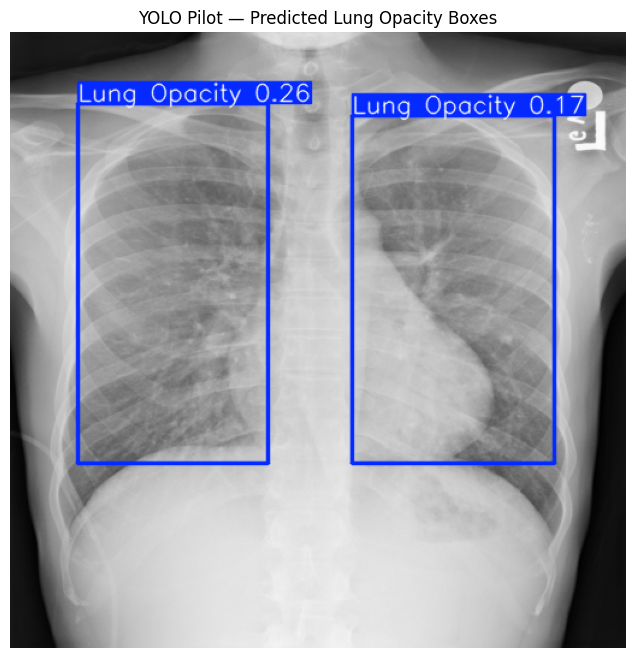

Validation image: 3d259836-0ac3-4608-8384-ea7b8473709d.png
Predicted boxes: 2


In [ ]:
from ultralytics import YOLO
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

model_path = (
    "/content/drive/MyDrive/pneumonia_detector/"
    "rsna_yolo_pilot_safe/weights/best.pt"
)

val_dir = "/content/rsna_yolo/images/val"

assert os.path.isfile(model_path), "Best YOLO weights not found."
assert os.path.isdir(val_dir), "Validation images not found."

detector = YOLO(model_path)

image_files = [
    os.path.join(val_dir, f)
    for f in os.listdir(val_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

image_path = random.choice(image_files)

results = detector.predict(
    source=image_path,
    imgsz=320,
    conf=0.15,
    device=0,
    save=False,
    verbose=False
)

annotated = results[0].plot()
annotated = annotated[:, :, ::-1]  # BGR to RGB for display

plt.figure(figsize=(8, 8))
plt.imshow(annotated)
plt.title("YOLO Pilot — Predicted Lung Opacity Boxes")
plt.axis("off")
plt.show()

print("Validation image:", os.path.basename(image_path))
print("Predicted boxes:", len(results[0].boxes))

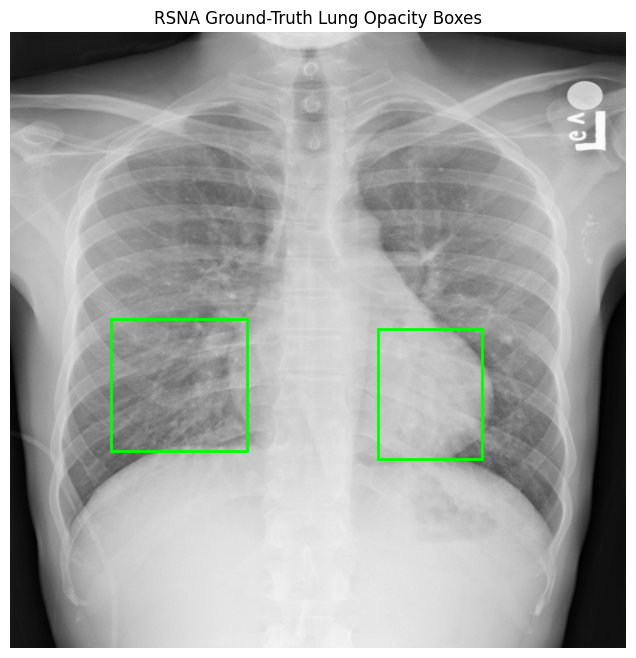

Ground-truth boxes: 2


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pydicom

data_dir = "/content/rsna_data"
labels_path = os.path.join(data_dir, "stage_2_train_labels.csv")
image_dir = os.path.join(data_dir, "stage_2_train_images")

# Use the validation image shown in your screenshot
patient_id = "3d259836-0ac3-4608-8384-ea7b8473709d"

# Load original DICOM image
ds = pydicom.dcmread(
    os.path.join(image_dir, patient_id + ".dcm")
)
image = ds.pixel_array

if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
    image = image.max() - image

# Find all ground-truth boxes for this image
labels = pd.read_csv(labels_path)
gt = labels[
    (labels["patientId"] == patient_id)
    & (labels["Target"] == 1)
].dropna(subset=["x", "y", "width", "height"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image, cmap="gray")

for _, row in gt.iterrows():
    rect = patches.Rectangle(
        (row["x"], row["y"]),
        row["width"],
        row["height"],
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rect)

ax.set_title("RSNA Ground-Truth Lung Opacity Boxes")
ax.axis("off")
plt.show()

print("Ground-truth boxes:", len(gt))

In [ ]:
import os
import numpy as np
import pandas as pd
import pydicom
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ultralytics import YOLO

patient_id = "3d259836-0ac3-4608-8384-ea7b8473709d"

model_path = (
    "/content/drive/MyDrive/pneumonia_detector/"
    "rsna_yolo_pilot_safe/weights/best.pt"
)
image_path = f"/content/rsna_yolo/images/val/{patient_id}.png"
dicom_path = f"/content/rsna_data/stage_2_train_images/{patient_id}.dcm"
labels_path = "/content/rsna_data/stage_2_train_labels.csv"

# Load detector and predict
detector = YOLO(model_path)
result = detector.predict(
    image_path, imgsz=320, conf=0.15, device=0, verbose=False
)[0]

pred_boxes = result.boxes.xyxy.cpu().numpy()

# Ground-truth annotations, normalized to the resized image dimensions
ds = pydicom.dcmread(dicom_path)
original_h, original_w = ds.pixel_array.shape
labels = pd.read_csv(labels_path)

gt_rows = labels[
    (labels["patientId"] == patient_id) & (labels["Target"] == 1)
].dropna(subset=["x", "y", "width", "height"])

image_h, image_w = cv2.imread(image_path).shape[:2]

gt_boxes = []
for _, row in gt_rows.iterrows():
    x1 = row["x"] / original_w * image_w
    y1 = row["y"] / original_h * image_h
    x2 = (row["x"] + row["width"]) / original_w * image_w
    y2 = (row["y"] + row["height"]) / original_h * image_h
    gt_boxes.append([x1, y1, x2, y2])

def calculate_iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

# Best predicted-box overlap for each ground-truth box
best_ious = []
for gt in gt_boxes:
    overlaps = [calculate_iou(gt, pred) for pred in pred_boxes]
    best_ious.append(max(overlaps, default=0.0))

print("Ground-truth boxes:", len(gt_boxes))
print("Predicted boxes:", len(pred_boxes))
print("Best IoU per ground-truth box:",
      [round(x, 3) for x in best_ious])
print("Mean best IoU:", round(float(np.mean(best_ious)), 3)
      if best_ious else 0.0)
print("Ground-truth boxes matched at IoU >= 0.5:",
      sum(x >= 0.5 for x in best_ious), "/", len(best_ious))

ModuleNotFoundError: No module named 'pydicom'

In [ ]:
import os
import torch
from ultralytics import YOLO

# Confirm GPU
if not torch.cuda.is_available():
    raise RuntimeError("GPU unavailable. Do not start training.")

print("GPU:", torch.cuda.get_device_name(0))

# Confirm dataset configuration and saved pilot weights
data_yaml = "/content/rsna_yolo/data.yaml"

previous_weights = (
    "/content/drive/MyDrive/pneumonia_detector/"
    "rsna_yolo_pilot_safe/weights/best.pt"
)

assert os.path.isfile(data_yaml), "YOLO data.yaml is missing."
assert os.path.isfile(previous_weights), "Previous best weights are missing."

# Continue from the best weights of the first pilot
detector = YOLO(previous_weights)

print("Loaded previous YOLO pilot weights.")

# Train a separate improvement experiment
results = detector.train(
    data=data_yaml,
    epochs=10,
    imgsz=512,
    batch=4,
    device=0,
    workers=2,
    amp=False,
    cache=False,
    project="/content/drive/MyDrive/pneumonia_detector",
    name="rsna_yolo_improved",
    exist_ok=True,
    patience=3,
    seed=42,
    plots=True
)

print("\nImprovement experiment finished.")
print(
    "Best weights:",
    "/content/drive/MyDrive/pneumonia_detector/"
    "rsna_yolo_improved/weights/best.pt"
)

GPU: Tesla T4
Loaded previous YOLO pilot weights.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/rsna_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/pneumonia_detector/rsna_yolo_pilot_safe/weights/be

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import random

# Load your trained detector from Google Drive
model_path = "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt"
detector = YOLO(model_path)

# Select one image from the validation dataset
val_dir = Path("/content/rsna_yolo/images/val")
images = list(val_dir.glob("*.png")) + list(val_dir.glob("*.jpg"))

if not images:
    raise FileNotFoundError(
        "No validation images found. Check that /content/rsna_yolo exists."
    )

image_path = random.choice(images)
print("Testing image:", image_path.name)

# Run detection
results = detector.predict(
    source=str(image_path),
    imgsz=512,
    conf=0.15,
    device=0,
    verbose=False
)

# Display image with predicted boxes
annotated = results[0].plot()
annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(annotated, cmap="gray")
plt.title("YOLO Lung Opacity Detection — Prediction")
plt.axis("off")
plt.show()

print("Predicted boxes:", len(results[0].boxes))

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.9 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import random

# Load your trained model
model_path = "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt"

detector = YOLO(model_path)

print("✅ YOLO detector loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

model_path = Path(
    "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt"
)

print("Model file exists:", model_path.exists())

if model_path.exists():
    print("Model size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))
else:
    print("The model was not found at this location.")

Model file exists: True
Model size (MB): 6.18


In [ ]:
from ultralytics import YOLO

model_path = "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt"

detector = YOLO(model_path)

print("✅ Trained YOLO detector loaded successfully!")

✅ Trained YOLO detector loaded successfully!


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2
import random

# Find validation images
val_dir = Path("/content/rsna_yolo/images/val")
images = list(val_dir.glob("*.png")) + list(val_dir.glob("*.jpg"))

if not images:
    raise FileNotFoundError(
        "Validation images not found. The dataset may need to be restored."
    )

# Select one image
image_path = random.choice(images)

# Predict bounding boxes
results = detector.predict(
    source=str(image_path),
    imgsz=512,
    conf=0.15,
    device=0,
    verbose=False
)

# Display prediction
annotated = results[0].plot()
annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(annotated)
plt.title("YOLO Lung Opacity Detection")
plt.axis("off")
plt.show()

print("Image:", image_path.name)
print("Predicted boxes:", len(results[0].boxes))

FileNotFoundError: Validation images not found. The dataset may need to be restored.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import drive

drive.mount("/content/drive")

zip_path = Path(
    "/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip"
)
data_dir = Path("/content/rsna_data")

if not zip_path.exists():
    print("ZIP not found at:", zip_path)
    print("Please check its location in Google Drive.")
else:
    image_dir = data_dir / "stage_2_train_images"
    labels_file = data_dir / "stage_2_train_labels.csv"

    if not image_dir.exists() or not labels_file.exists():
        print("Restoring dataset files...")
        data_dir.mkdir(parents=True, exist_ok=True)

        with ZipFile(zip_path, "r") as z:
            z.extractall(data_dir)

    print("Dataset folder exists:", image_dir.exists())
    print("Labels file exists:", labels_file.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Restoring dataset files...
Dataset folder exists: True
Labels file exists: True


In [ ]:
from pathlib import Path

val_dir = Path("/content/rsna_yolo/images/val")
images = []

if val_dir.exists():
    images = (
        list(val_dir.glob("*.png"))
        + list(val_dir.glob("*.jpg"))
        + list(val_dir.glob("*.jpeg"))
    )

print("Validation folder exists:", val_dir.exists())
print("Validation images found:", len(images))

Validation folder exists: False
Validation images found: 0


In [ ]:
from pathlib import Path

paths = [
    "/content/rsna_yolo",
    "/content/rsna_yolo/images",
    "/content/rsna_yolo/images/train",
    "/content/rsna_yolo/labels",
    "/content/rsna_yolo/labels/train",
]

for p in paths:
    path = Path(p)
    print(p, "->", "Exists" if path.exists() else "Missing")

/content/rsna_yolo -> Missing
/content/rsna_yolo/images -> Missing
/content/rsna_yolo/images/train -> Missing
/content/rsna_yolo/labels -> Missing
/content/rsna_yolo/labels/train -> Missing


In [ ]:
from pathlib import Path

dicom_dir = Path("/content/rsna_data/stage_2_train_images")

print("Original image folder exists:", dicom_dir.exists())

if dicom_dir.exists():
    files = list(dicom_dir.glob("*.dcm"))
    print("DICOM files found:", len(files))

Original image folder exists: True
DICOM files found: 26684


In [ ]:
!pip install -q pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 26.5 MB/s eta 0:00:00


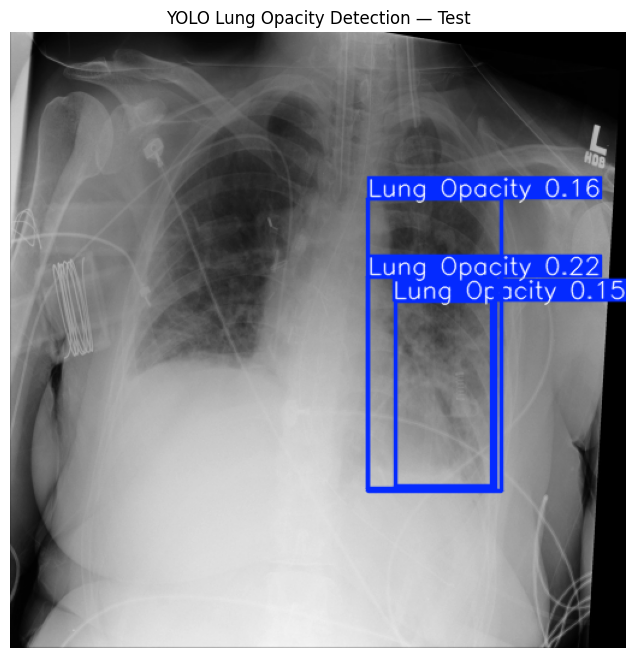

Test image: 7ef28198-53a4-408e-8a54-1d421c97edba.dcm
Predicted boxes: 3


In [ ]:
from pathlib import Path
import pydicom
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Find one original DICOM image
dicom_dir = Path("/content/rsna_data/stage_2_train_images")
dicom_files = list(dicom_dir.glob("*.dcm"))

if not dicom_files:
    raise FileNotFoundError("No DICOM files found.")

# Read and convert the X-ray to a temporary PNG
ds = pydicom.dcmread(str(dicom_files[0]))
pixels = ds.pixel_array.astype(np.float32)
pixels -= pixels.min()

if pixels.max() > 0:
    pixels = pixels / pixels.max() * 255

image = pixels.astype(np.uint8)
image = cv2.resize(image, (512, 512))

# Run your saved detector
results = detector.predict(
    source=image,
    imgsz=512,
    conf=0.15,
    device=0,
    verbose=False
)

# Display predicted boxes
annotated = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 8))
plt.imshow(annotated)
plt.title("YOLO Lung Opacity Detection — Test")
plt.axis("off")
plt.show()

print("Test image:", dicom_files[0].name)
print("Predicted boxes:", len(results[0].boxes))

In [ ]:
import pandas as pd
from pathlib import Path

labels_path = Path("/content/rsna_data/stage_2_train_labels.csv")
df = pd.read_csv(labels_path)

# Identify the X-ray tested by YOLO
image_id = dicom_files[0].stem

# Get the radiologist's annotations
ground_truth = df[
    (df["patientId"] == image_id) &
    (df["Target"] == 1)
]

print("Image ID:", image_id)
print("Ground-truth opacity boxes:", len(ground_truth))

if len(ground_truth) > 0:
    display(ground_truth[["x", "y", "width", "height"]])
else:
    print("No positive opacity boxes are recorded for this image.")

Image ID: 7ef28198-53a4-408e-8a54-1d421c97edba
Ground-truth opacity boxes: 2


,x,y,width,height
12440,230.0,450.0,115.0,95.0
12441,673.0,478.0,133.0,138.0


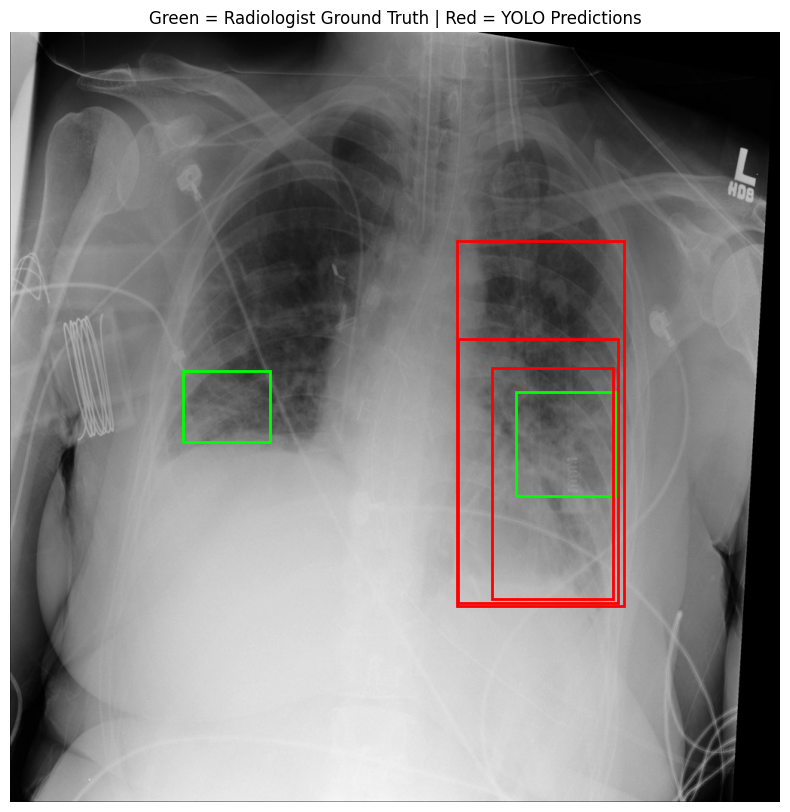

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import cv2

# Original image and model predictions from the previous cell
image_id = dicom_files[0].stem

# Ground-truth boxes from the RSNA CSV use original DICOM pixel coordinates
ds = pydicom.dcmread(str(dicom_files[0]))
original_image = ds.pixel_array.astype(np.float32)

# Apply DICOM display inversion if needed
if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
    original_image = original_image.max() - original_image

# Show original image in its native dimensions
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(original_image, cmap="gray")

# Draw ground-truth boxes in GREEN
for _, row in ground_truth.iterrows():
    rect = patches.Rectangle(
        (row["x"], row["y"]),
        row["width"],
        row["height"],
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )
    ax.add_patch(rect)

# Draw YOLO predictions in RED, mapped from 512x512 back to original dimensions
h, w = original_image.shape[:2]
for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    x1, x2 = x1 * w / 512, x2 * w / 512
    y1, y2 = y1 * h / 512, y2 * h / 512

    rect = patches.Rectangle(
        (x1, y1), x2 - x1, y2 - y1,
        linewidth=2, edgecolor="red", facecolor="none"
    )
    ax.add_patch(rect)

ax.set_title("Green = Radiologist Ground Truth | Red = YOLO Predictions")
ax.axis("off")
plt.show()

In [ ]:
import numpy as np

# Ground-truth boxes in original image pixel coordinates
gt_boxes = ground_truth[["x", "y", "width", "height"]].to_numpy(dtype=float)
gt_boxes = np.column_stack([
    gt_boxes[:, 0],
    gt_boxes[:, 1],
    gt_boxes[:, 0] + gt_boxes[:, 2],
    gt_boxes[:, 1] + gt_boxes[:, 3]
])

# YOLO boxes: convert from 512x512 coordinates to original image coordinates
h, w = original_image.shape[:2]
pred_boxes = results[0].boxes.xyxy.cpu().numpy().astype(float)
pred_boxes[:, [0, 2]] *= w / 512
pred_boxes[:, [1, 3]] *= h / 512

def calculate_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0.0

for i, gt in enumerate(gt_boxes, start=1):
    scores = [calculate_iou(gt, pred) for pred in pred_boxes]
    best_iou = max(scores, default=0.0)
    print(f"Ground-truth box {i}: best IoU = {best_iou:.3f}")

Ground-truth box 1: best IoU = 0.000
Ground-truth box 2: best IoU = 0.355


In [ ]:
from pathlib import Path

files = {
    "Binary classifier": "/content/drive/MyDrive/pneumonia_efficientnet.keras",
    "YOLO detector": "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt",
}

for name, path in files.items():
    p = Path(path)
    print(f"{name}: {'READY' if p.exists() else 'MISSING'}")
    if p.exists():
        print(f"  Size: {p.stat().st_size / (1024**2):.1f} MB")

Binary classifier: READY
  Size: 16.3 MB
YOLO detector: READY
  Size: 6.2 MB


In [ ]:
!pip -q install gradio ultralytics

import numpy as np
import tensorflow as tf
import gradio as gr
import cv2
from PIL import Image
from ultralytics import YOLO

# Load the saved models
classifier = tf.keras.models.load_model(
    "/content/drive/MyDrive/pneumonia_efficientnet.keras"
)

detector = YOLO(
    "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt"
)

print("Both models loaded successfully.")

def analyze_xray(image):
    if image is None:
        return None, "Please upload a chest X-ray.", None

    # Prepare image for EfficientNet classifier
    rgb = np.array(image.convert("RGB"))
    resized = cv2.resize(rgb, (224, 224))
    x = np.expand_dims(resized.astype(np.float32), axis=0)

    # Original binary model outputs pneumonia probability
    probability = float(classifier.predict(x, verbose=0).reshape(-1)[0])
    threshold = 0.40

    prediction = "PNEUMONIA" if probability >= threshold else "NORMAL"
    report = (
        f"**Classification: {prediction}**\n\n"
        f"Pneumonia probability: {probability:.1%}\n\n"
        f"Normal probability: {1-probability:.1%}\n\n"
        f"Screening threshold: {threshold:.0%}"
    )

    # Run YOLO detector
    detection = detector.predict(
        source=rgb,
        imgsz=512,
        conf=0.15,
        verbose=False
    )[0]

    # Render predicted bounding boxes
    boxed = detection.plot()
    boxed = cv2.cvtColor(boxed, cv2.COLOR_BGR2RGB)

    count = len(detection.boxes)
    report += f"\n\nYOLO predicted boxes: {count}"

    return Image.fromarray(rgb), report, Image.fromarray(boxed)

with gr.Blocks(title="Pneumonia Detection Prototype") as demo:
    gr.Markdown("# 🫁 Pneumonia Detection Prototype")
    gr.Markdown(
        "AI-assisted chest X-ray classification using EfficientNet-B0 "
        "with YOLO-based lung opacity region proposals."
    )

    gr.Markdown(
        "**Research prototype only — not a medical device and not intended "
        "for clinical diagnosis. Predictions and boxes may be incorrect.**"
    )

    upload = gr.Image(type="pil", label="Upload chest X-ray")
    run = gr.Button("Analyze X-ray", variant="primary")

    classification = gr.Markdown(label="Classification")
    original = gr.Image(label="Input X-ray")
    boxed = gr.Image(label="YOLO predicted regions")

    run.click(
        fn=analyze_xray,
        inputs=upload,
        outputs=[original, classification, boxed]
    )

demo.launch(share=True)

Both models loaded successfully.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e13d7eabfa1615268a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import numpy as np
import tensorflow as tf
import gradio as gr
import cv2
from PIL import Image
from ultralytics import YOLO

# Load both saved models
classifier = tf.keras.models.load_model(
    "/content/drive/MyDrive/pneumonia_efficientnet.keras"
)

detector = YOLO(
    "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt"
)

def analyze_xray(image):
    if image is None:
        return None, "Please upload a chest X-ray.", None

    rgb = np.array(image.convert("RGB"))

    # EfficientNet classification
    resized = cv2.resize(rgb, (224, 224))
    x = np.expand_dims(resized.astype(np.float32), axis=0)
    probability = float(
        classifier.predict(x, verbose=0).reshape(-1)[0]
    )

    prediction = "PNEUMONIA" if probability >= 0.40 else "NORMAL"

    report = (
        f"### Classification: {prediction}\n\n"
        f"**Pneumonia probability:** {probability:.1%}\n\n"
        f"**Normal probability:** {1 - probability:.1%}\n\n"
        "*Research prototype only — not intended for clinical diagnosis.*"
    )

    # YOLO detection — keep the boxes drawn on the X-ray
    result = detector.predict(
        source=rgb,
        imgsz=512,
        conf=0.15,
        verbose=False
    )[0]

    boxed = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    # Hide the box count and threshold from the written results
    return Image.fromarray(rgb), report, Image.fromarray(boxed)

with gr.Blocks(title="Pneumonia Detection Prototype") as demo:
    gr.Markdown("# 🫁 Pneumonia Detection Prototype")
    gr.Markdown(
        "AI-assisted chest X-ray classification using EfficientNet-B0 "
        "and YOLO-based opacity region detection."
    )
    gr.Markdown(
        "**Research prototype only — not a medical device and not intended "
        "for clinical diagnosis.**"
    )

    upload = gr.Image(type="pil", label="Upload chest X-ray")
    run = gr.Button("Analyze X-ray", variant="primary")

    original = gr.Image(label="Input X-ray")
    classification = gr.Markdown(label="Classification")
    boxed = gr.Image(label="YOLO-predicted regions")

    run.click(
        fn=analyze_xray,
        inputs=upload,
        outputs=[original, classification, boxed]
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d76af996bf8309313a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


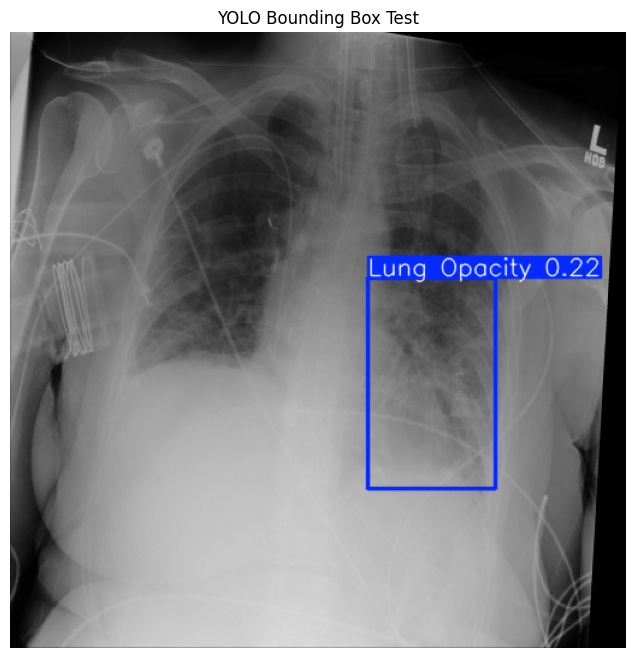

Predicted boxes: 1


In [ ]:
import cv2
import matplotlib.pyplot as plt

# Reuse the existing original X-ray and loaded detector
image = cv2.resize(
    dicom_files[0] and pydicom.dcmread(str(dicom_files[0])).pixel_array,
    (512, 512)
)

results_test = detector.predict(
    source=image,
    imgsz=512,
    conf=0.15,
    iou=0.35,
    max_det=5,
    verbose=False
)

annotated = cv2.cvtColor(
    results_test[0].plot(),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 8))
plt.imshow(annotated, cmap="gray")
plt.title("YOLO Bounding Box Test")
plt.axis("off")
plt.show()

print("Predicted boxes:", len(results_test[0].boxes))

In [ ]:
from pathlib import Path

paths = {
    "Training images": "/content/rsna_yolo/images/train",
    "Training labels": "/content/rsna_yolo/labels/train",
    "Validation images": "/content/rsna_yolo/images/val",
    "Validation labels": "/content/rsna_yolo/labels/val",
    "Dataset config": "/content/rsna_yolo/data.yaml",
    "Saved detector": "/content/drive/MyDrive/pneumonia_detector/rsna_yolo_improved/weights/best.pt",
}

for name, path in paths.items():
    print(f"{name}: {'READY' if Path(path).exists() else 'MISSING'}")

Training images: MISSING
Training labels: MISSING
Validation images: MISSING
Validation labels: MISSING
Dataset config: MISSING
Saved detector: READY


In [ ]:
!pip -q install pydicom pyyaml

import pandas as pd
import numpy as np
import pydicom
import cv2
import yaml
from pathlib import Path
from zipfile import ZipFile
from sklearn.model_selection import train_test_split

# Restore original dataset if needed
zip_path = Path("/content/drive/MyDrive/rsna-pneumonia-detection-challenge.zip")
data_dir = Path("/content/rsna_data")
dicom_dir = data_dir / "stage_2_train_images"
csv_path = data_dir / "stage_2_train_labels.csv"

if not csv_path.exists() or not dicom_dir.exists():
    with ZipFile(zip_path) as z:
        z.extractall(data_dir)

# Load annotations and retain positive images with boxes
df = pd.read_csv(csv_path)
positive = df[df["Target"] == 1].copy()
patient_ids = positive["patientId"].unique()

train_ids, val_ids = train_test_split(
    patient_ids, test_size=0.2, random_state=42
)

out = Path("/content/rsna_yolo")
for split in ["train", "val"]:
    (out / "images" / split).mkdir(parents=True, exist_ok=True)
    (out / "labels" / split).mkdir(parents=True, exist_ok=True)

# Convert DICOM images and annotations to YOLO format
for split, ids in [("train", set(train_ids)), ("val", set(val_ids))]:
    for patient_id in ids:
        dcm_path = dicom_dir / f"{patient_id}.dcm"
        if not dcm_path.exists():
            continue

        ds = pydicom.dcmread(str(dcm_path))
        pixels = ds.pixel_array.astype(np.float32)
        pixels -= pixels.min()
        if pixels.max() > 0:
            pixels = pixels / pixels.max() * 255

        h, w = pixels.shape
        img = cv2.resize(pixels.astype(np.uint8), (512, 512))
        cv2.imwrite(str(out / "images" / split / f"{patient_id}.png"), img)

        rows = positive[positive["patientId"] == patient_id]
        lines = []
        for _, r in rows.iterrows():
            xc = (r["x"] + r["width"] / 2) / w
            yc = (r["y"] + r["height"] / 2) / h
            bw = r["width"] / w
            bh = r["height"] / h
            lines.append(
                f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
            )

        (out / "labels" / split / f"{patient_id}.txt").write_text(
            "\n".join(lines)
        )

yaml.safe_dump({
    "path": str(out),
    "train": "images/train",
    "val": "images/val",
    "names": {0: "Lung Opacity"}
}, open(out / "data.yaml", "w"))

print("Dataset rebuilt.")
print("Training images:", len(list((out / "images/train").glob("*.png"))))
print("Validation images:", len(list((out / "images/val").glob("*.png"))))
print("Saved detector remains in Google Drive; no training performed.")

Dataset rebuilt.
Training images: 4809
Validation images: 1203
Saved detector remains in Google Drive; no training performed.
